### Libraries

In [187]:
import os
import numpy as np
import nibabel as nb
from scipy.ndimage import gaussian_filter1d
import matplotlib.pyplot as plt
import helpers
import copy
from brainspace.mesh.mesh_io import read_surface
from brainspace.mesh.array_operations import smooth_array
from brainspace.datasets import load_mask
from brainspace.plotting import plot_hemispheres
from scipy.interpolate import griddata
from scipy.stats import zscore
from scipy import stats
import scipy as sp
import pandas as pd
import seaborn as sns
import matplotlib.colors as mcolors
import utils_RRC
import matplotlib.colors as mcolors
from statsmodels.nonparametric.smoothers_lowess import lowess
from brainspace.null_models import SpinPermutations
from scipy.stats import rankdata
from scipy.stats import spearmanr
from scipy.stats import pearsonr

### Variables

In [2]:
# Set dataset PNI as working directory
os.chdir('/data_/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0')

# Path to MICAPIPEsurf = mask_5k !
micapipe=os.popen("echo $MICAPIPE").read()[:-1]

# Load native mid surface
inf_lh = read_surface(micapipe + '/surfaces/fsLR-5k.L.inflated.surf.gii', itype='gii')
inf_rh = read_surface(micapipe + '/surfaces/fsLR-5k.R.inflated.surf.gii', itype='gii')

mask_lh =  nb.load(micapipe + '/surfaces/fsLR-5k.L.mask.shape.gii').darrays[0].data
mask_rh =  nb.load(micapipe + '/surfaces/fsLR-5k.R.mask.shape.gii').darrays[0].data
mask_5k = np.concatenate((mask_lh, mask_rh), axis=0)
# Labels and boolean mask
mask_surf = mask_5k != 0

f5k_lh = read_surface(micapipe + '/surfaces/fsLR-5k.L.surf.gii', itype='gii')
f5k_rh = read_surface(micapipe + '/surfaces/fsLR-5k.R.surf.gii', itype='gii')

In [3]:
AFD_par_5k = np.load("/host/verges/tank/data/youngeun/myjupyter/array/AFD_par_average_SWM2mm_fsLR5k_norm.npy")
AFD_perp_5k = np.load("/host/verges/tank/data/youngeun/myjupyter/array/AFD_perpav_average_SWM2mm_fsLR5k_norm.npy")

### Functions

In [4]:
# Smooth intencities
def smooth_surf(surf_l, surf_r, points, Mask, Kernel='uniform', Niter=3, Relax=0.35):
    '''
    This function smooth an array (left and right) on a given surface
    Parameters
    ----------
    surf_l : np.array left surface 
    surf_r : np.array right surface
    points : np.array surface data
    Kernel : {'uniform', 'gaussian', 'inverse_distance'}
    Niter  : int, optional Number of smooth iterations
    Relax  : relax : float, optional relaxation factor
    Mask   : str or 1D ndarray, optional
    Returns
    -------
    sdata : smoothed numpy array
    
    '''
    Ndim = Mask.shape[0] 
    n2dim = int(Ndim/2)
    Mask_l=Mask[0:n2dim]
    Mask_r=Mask[n2dim:Ndim]
    sdata = np.concatenate((smooth_array(surf_l, points[0:n2dim],kernel=Kernel, n_iter=Niter,relax=Relax, mask=Mask_l), 
                          smooth_array(surf_r, points[n2dim:Ndim],kernel=Kernel, n_iter=Niter,relax=Relax, mask=Mask_r)), axis=0)
    return(sdata)

# Smooth each intencity
def smooth_intensities(int_profile):
    smoothed_i = np.copy(int_profile)
   
    # smooth each intensity
    for i in range(int_profile.shape[0]):
        smoothed_i[i,:] = smooth_surf(inf_lh, inf_rh, int_profile[i,:], mask_surf, Niter=5, Relax=0.5, Kernel='uniform')
   
    return(smoothed_i)

def map_to_labels5k(mpc_sliced, mask):
    # Get the index of the non medial wall regions
    mask_indx = np.where(mask==1)[0]
    # map to the labels
    labels_5k = np.full(mask.shape, np.nan)
    labels_5k[mask_indx] = mpc_sliced
    return(labels_5k)

In [5]:
def emp_variogram_vwise_conn(x,D,nh,h_bounds=0):
    #calculate empirical variogram for each vertex

    n = x.shape[0]
    triu = np.triu_indices(n, k=1)  # upper triangular inds
    b=3

    diff_ij = 1-x
    u_full=D[triu]


    vw_ev=np.zeros([n,nh])
    vw_h=np.zeros([n,nh])
    for vert in range(n):
        
        diff_ij_vw=diff_ij[vert,:]
        diff_ij_vw=np.delete(diff_ij_vw,vert)
        v = 0.5 * np.square(diff_ij_vw)
        v = np.square(diff_ij_vw)
        u=D[vert,:]
        u=np.delete(u,vert)
        if h_bounds==0:
            h = np.linspace(u.min(), u.max(), nh)
        else: 
            h = np.linspace(h_bounds[0], h_bounds[1], nh)
        # Subtract each h from each pairwise distance u
        # Each row corresponds to a unique h
        du = np.abs(u - h[:, None])
        w = np.exp(-np.square(2.68 * du / b) / 2)
        denom = np.nansum(w, axis=1)
        wv = w * v[None, :]
        num = np.nansum(wv, axis=1)
        ev = num / denom #empirical variogram
        vw_ev[vert,:]=ev
        vw_h[vert,:]=h
    
    return vw_h, vw_ev

## Load Geodesic distance connectome

In [6]:
# -------------------------------
# Parameters
# -------------------------------
num_bins = 20
dist_range = [0, 160]
base = "/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0"

subjects = ["PNC003", "PNC006", "PNC011", "PNC018", "PNC019", "PNC022", "PNC024", "PNC025", "PNC026", "PNC037", "PNC038"]
sessions = ["03", "03", "03", "03", "03", "03", "a2", "a1", "a1", "a1", "a1"]

numFiles = len(subjects)
n_vert_l = np.sum(mask_5k[:4842] == 1)
n_vert_r = np.sum(mask_5k[4842:] == 1)

# -------------------------------
# Containers
# -------------------------------
ind_fc_hVw_l = np.zeros((numFiles, n_vert_l, num_bins))
ind_fc_evVw_l = np.zeros((numFiles, n_vert_l, num_bins))
ind_fc_hVw_r = np.zeros((numFiles, n_vert_r, num_bins))
ind_fc_evVw_r = np.zeros((numFiles, n_vert_r, num_bins))

GD_group_l = None
GD_group_r = None
FC_group_l = None
FC_group_r = None

# -------------------------------
# Subject loop
# -------------------------------
for i, (sub, ses) in enumerate(zip(subjects, sessions)):

    print(f"Processing {sub}")

    cnt_fc = (
        f"{base}/sub-{sub}/ses-{ses}/func/desc-me_task-rest_bold/surf/"
        f"sub-{sub}_ses-{ses}_surf-fsLR-5k_desc-FC.shape.gii"
    )

    cnt_gd = (
        f"{base}/sub-{sub}/ses-{ses}/dist/"
        f"sub-{sub}_ses-{ses}_surf-fsLR-5k_GD.shape.gii"
    )

    FC = nb.load(cnt_fc).darrays[0].data
    # Fisher transform
    FCz = np.arctanh(FC)
    #FCz = np.tanh(FCz)
    # replace inf with 0
    FCz[~np.isfinite(FCz)] = 0
    GD = nb.load(cnt_gd).darrays[0].data

    # hemisphere split
    fc_left  = FCz[:4842, :4842]
    fc_right = FCz[4842:, 4842:]
    gd_left  = GD[:4842, :4842]
    gd_right = GD[4842:, 4842:]

    # midwall masking
    fc_left_masked  = fc_left[np.ix_(mask_5k[:4842] == 1, mask_5k[:4842] == 1)]
    fc_right_masked = fc_right[np.ix_(mask_5k[4842:] == 1, mask_5k[4842:] == 1)]
    gd_left_masked  = gd_left[np.ix_(mask_5k[:4842] == 1, mask_5k[:4842] == 1)]
    gd_right_masked = gd_right[np.ix_(mask_5k[4842:] == 1, mask_5k[4842:] == 1)]
    
    # ---------------------------
    # Group FC accumulation (Fisher z)
    # ---------------------------
    FC_z_l = copy.deepcopy(fc_left_masked)
    np.fill_diagonal(FC_z_l, 3)

    FC_z_r = copy.deepcopy(fc_right_masked)
    np.fill_diagonal(FC_z_r, 3)

    if i == 0:
        FC_group_l = FC_z_l.copy()
        FC_group_r = FC_z_r.copy()
    else:
        FC_group_l += FC_z_l
        FC_group_r += FC_z_r

    if i == 0:
        GD_group_l = gd_left_masked.copy()
        GD_group_r = gd_right_masked.copy()
    else:
        GD_group_l += gd_left_masked
        GD_group_r += gd_right_masked
  
    # ---------------------------
    # Empirical variogram
    # ---------------------------
    hVw_l, evVw_l = helpers.emp_variogram_vwise_conn(fc_left_masked, gd_left_masked, num_bins, dist_range)
    hVw_r, evVw_r = helpers.emp_variogram_vwise_conn(fc_right_masked, gd_right_masked, num_bins, dist_range)

    ind_fc_hVw_l[i, :, :] = hVw_l
    ind_fc_evVw_l[i, :, :] = evVw_l
    ind_fc_hVw_r[i, :, :] = hVw_r
    ind_fc_evVw_r[i, :, :] = evVw_r

Processing PNC003


/tmp/ipykernel_137814/1848507316.py:47: RuntimeWarning: divide by zero encountered in arctanh
  FCz = np.arctanh(FC)


Processing PNC006
Processing PNC011
Processing PNC018
Processing PNC019
Processing PNC022
Processing PNC024
Processing PNC025
Processing PNC026
Processing PNC037
Processing PNC038


## Vertex-wise Variogram

In [7]:
from scipy.optimize import curve_fit
import numpy as np

# -----------------------------------
# Exponential variogram model
# -----------------------------------
def exponential(h, r, c0, nugget):

    # practical range parameterization
    theoVar = nugget + c0 * (1 - np.exp(-h / (r / 3)))

    return theoVar

# -----------------------------------
# Parameters
# -----------------------------------
clipStart = 1
clipEnd   = 19

n_sub = numFiles
n_vert_l = ind_fc_hVw_l.shape[1]
n_vert_r = ind_fc_hVw_r.shape[1]

# -----------------------------------
# Containers
# -----------------------------------
sill_ind_l  = np.full((n_sub, n_vert_l), np.nan)
range_ind_l = np.full((n_sub, n_vert_l), np.nan)

sill_ind_r  = np.full((n_sub, n_vert_r), np.nan)
range_ind_r = np.full((n_sub, n_vert_r), np.nan)


# ===================================
# LEFT hemisphere
# ===================================
for s in range(n_sub):

    for v in range(n_vert_l):

        # empirical variogram
        x = ind_fc_hVw_l[s, v, clipStart:clipEnd]
        y = ind_fc_evVw_l[s, v, clipStart:clipEnd]

        # remove NaNs
        mask = ~np.isnan(x) & ~np.isnan(y)

        x = x[mask]
        y = y[mask]

        # skip insufficient data
        if len(x) < 5:
            continue

        try:

            # -----------------------------------
            # bounds and initial guesses
            # (same logic as original code)
            # -----------------------------------
            bounds = (0.00001,[np.nanmax(x), np.nanmax(y), np.nanmax(y)/10]) #range, partial sill, nugget
            p0 = bounds[1]
        
            # -----------------------------------
            # Fit exponential model
            # -----------------------------------
            popt, _ = curve_fit(exponential, x, y, method='trf', p0=p0, bounds=bounds, maxfev=5000)
            fitted_r, fitted_c0, fitted_nugget = popt

            # -----------------------------------
            # Store parameters
            # -----------------------------------
            sill_ind_l[s, v]  = fitted_c0 #+ fitted_nugget
            range_ind_l[s, v] = fitted_r

        except:
            continue

# ===================================
# RIGHT hemisphere
# ===================================
for s in range(n_sub):
    for v in range(n_vert_r):

        x = ind_fc_hVw_r[s, v, clipStart:clipEnd]
        y = ind_fc_evVw_r[s, v, clipStart:clipEnd]

        mask = ~np.isnan(x) & ~np.isnan(y)

        x = x[mask]
        y = y[mask]

        if len(x) < 5:
            continue

        try:

            # -----------------------------------
            # bounds and initial guesses
            # (same logic as original code)
            # -----------------------------------
            bounds = (0.00001,[np.nanmax(x), np.nanmax(y), np.nanmax(y)/10]) #range, partial sill, nugget
            p0 = bounds[1]

            popt, _ = curve_fit(exponential, x, y, method='trf', p0=p0, bounds=bounds, maxfev=5000)
            fitted_r, fitted_c0, fitted_nugget = popt

            sill_ind_r[s, v]  = fitted_c0 #+ fitted_nugget
            range_ind_r[s, v] = fitted_r

        except:
            continue

# -----------------------------------
# GROUP AVERAGE
# -----------------------------------
sill_group_l  = np.nanmean(sill_ind_l, axis=0)
range_group_l = np.nanmean(range_ind_l, axis=0)

sill_group_r  = np.nanmean(sill_ind_r, axis=0)
range_group_r = np.nanmean(range_ind_r, axis=0)

# -----------------------------------
# Combine hemispheres
# -----------------------------------
sill_group  = np.concatenate((sill_group_l,  sill_group_r))
range_group = np.concatenate((range_group_l, range_group_r))

In [8]:
grp_sill = map_to_labels5k(sill_group, mask_5k)
grp_range = map_to_labels5k(range_group, mask_5k)

In [9]:
# Make 2D arrays
maps_to_smooth = np.vstack([grp_sill, grp_range])  # shape (2, n_vertices)

# Smooth each map
smoothed_maps = smooth_intensities(maps_to_smooth)  # shape (2, n_vertices)

grp_sill_smooth  = smoothed_maps[0, :]
grp_range_smooth = smoothed_maps[1, :]

In [10]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# min=blue, mid=gray, max=red
colors = [
    (0.159, 0.4, 0.675),  # blue
    (1.0, 0.84, 0.61),  # gray
    (0.698, 0.094, 0.169)   # red
]

custom_cmap = LinearSegmentedColormap.from_list("BlueGrayRed", colors)

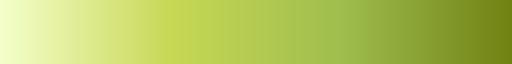

In [11]:
import colormaps as clrmps
import cmocean
clrmps.green_c_gry1_r

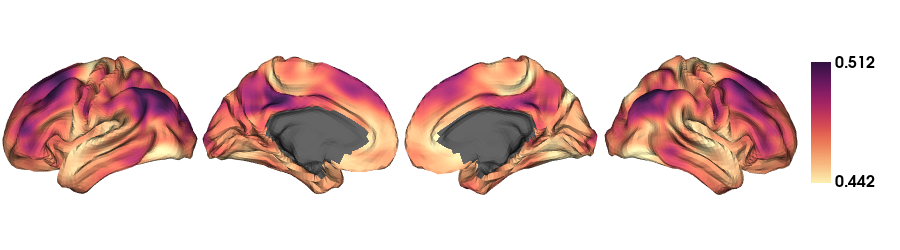

In [12]:
scrange=(np.quantile(grp_sill_smooth[mask_5k==True], 0.01), np.quantile(grp_sill_smooth[mask_5k==True], 0.99))
# Plot average SWM surfaces
plot_hemispheres(f5k_lh, f5k_rh, array_name=grp_sill_smooth, size=(900, 250), color_bar='right', zoom=1.25, embed_nb=True, interactive=False, share='both', nan_color=(0.3, 0.3, 0.3, 1),
                 cmap='cmo.matter', transparent_bg=False, screenshot=False, color_range=scrange)

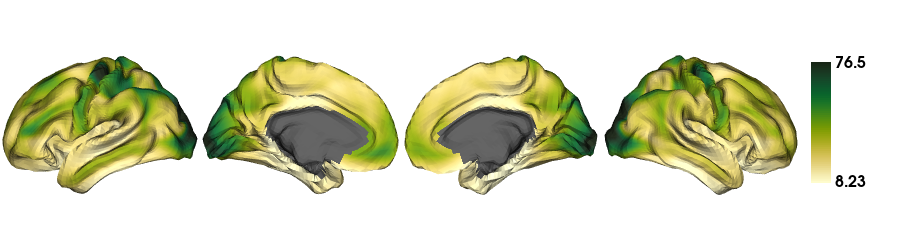

In [13]:
rcrange=(np.quantile(grp_range_smooth[mask_5k==True], 0.01), np.quantile(grp_range_smooth[mask_5k==True], 0.99))
# Plot average SWM surfaces
plot_hemispheres(f5k_lh, f5k_rh, array_name=grp_range_smooth, size=(900, 250), color_bar='right', zoom=1.25, embed_nb=True, interactive=False, share='both', nan_color=(0.3, 0.3, 0.3, 1), 
                 cmap='cmo.speed', transparent_bg=False, screenshot=False, color_range=rcrange)

## Linear regression with U-fiber/Long-range fiber

In [14]:
def masked_zscore(data, mask):
    out = np.full_like(data, np.nan, dtype=float)
    out[mask] = zscore(data[mask], nan_policy='omit')   
    return out

In [15]:
# 1) Difference maps (Δ = parallel – perpendicular)
dAFD = AFD_par_5k - AFD_perp_5k

# 2) Z-score normalization
dAFD_z = masked_zscore(dAFD, mask_surf)

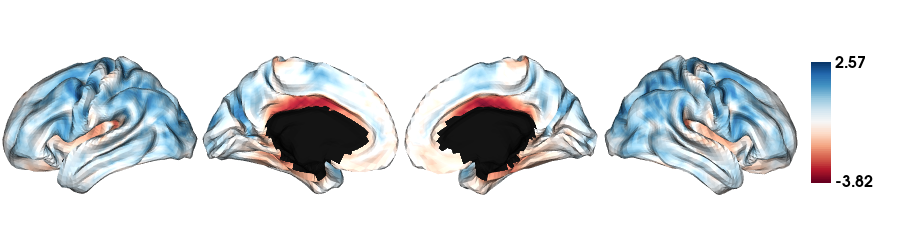

In [16]:
#dAFD_z[mask_5k==False] = np.nan
# Plot average SWM surfaces
plot_hemispheres(f5k_lh, f5k_rh, array_name=dAFD_z, size=(900, 250), color_bar='right', zoom=1.25, embed_nb=True, interactive=False, share='both', nan_color=(0, 0, 0, 1), 
                 cmap='RdBu', transparent_bg=False, screenshot=False)

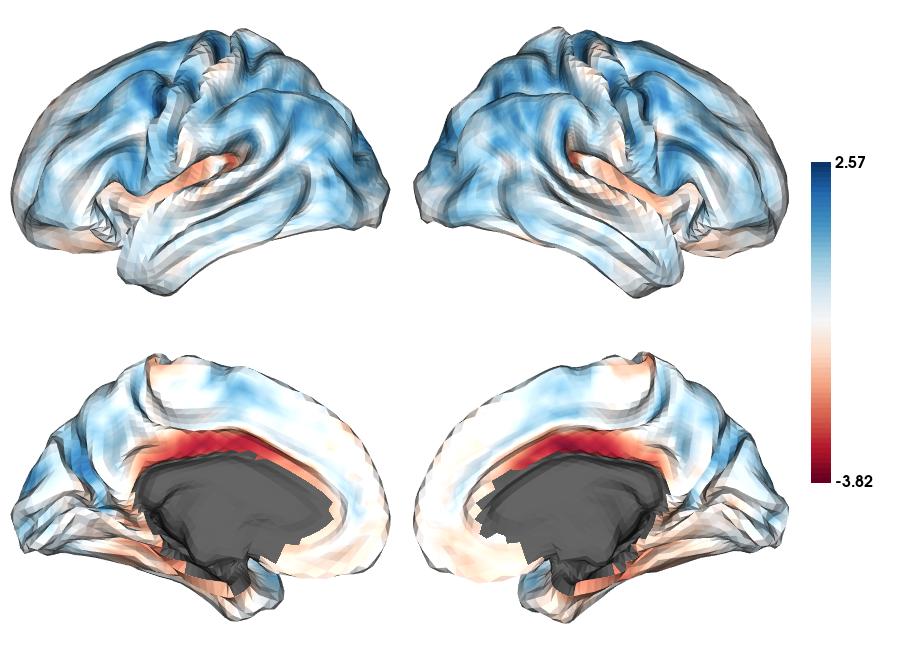

In [17]:
#dAFD_z[mask_5k==False] = np.nan
# Plot average SWM surfaces
plot_hemispheres(f5k_lh, f5k_rh, array_name=dAFD_z, size=(900, 650), color_bar='right', zoom=1.5, embed_nb=True, interactive=False, share='both', nan_color=(0.3, 0.3, 0.3, 1), 
                 cmap='RdBu', layout_style='grid', transparent_bg=False, screenshot=False)

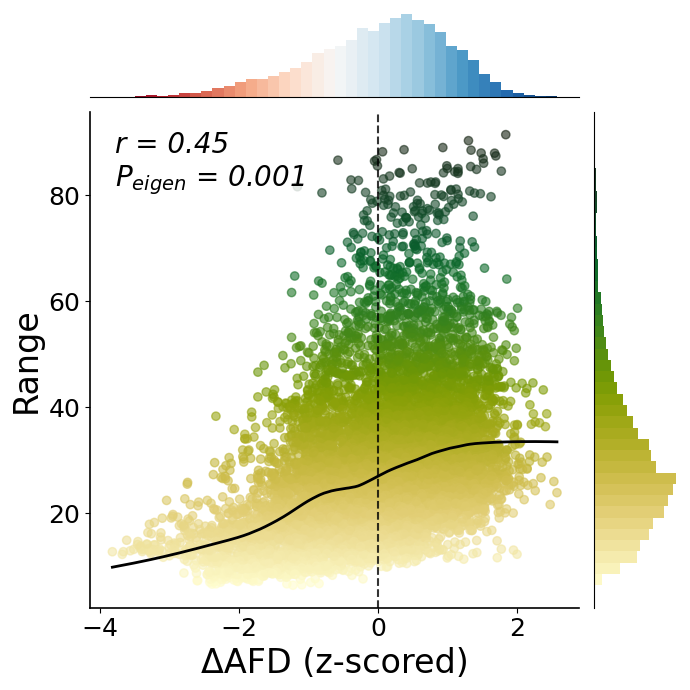

In [193]:
# -------------------------------------------------
# Prepare Data
# -------------------------------------------------
mod1 = copy.deepcopy(dAFD_z)
mod2 = copy.deepcopy(grp_range_smooth)

valid = ~np.isnan(mod1) & ~np.isnan(mod2)
x = mod1[valid]
y = mod2[valid]

# Spearman correlation
r, p = stats.spearmanr(x, y)

# -------------------------------------------------
# Create JointGrid
# -------------------------------------------------
g = sns.JointGrid(x=x, y=y, height=7, space=0)

# -------------------------------------------------
# Scatter colormap (BASED ON Y)
# -------------------------------------------------
ymin, ymax = np.min(y), np.max(y)

# robust normalization
if ymin < 0 < ymax:
    norm_scatter = mcolors.TwoSlopeNorm(
        vmin=ymin,
        vcenter=0,
        vmax=ymax
    )
else:
    norm_scatter = mcolors.Normalize(
        vmin=ymin,
        vmax=ymax
    )

sc = g.ax_joint.scatter(
    x, y,
    c=y,
    cmap='cmo.speed',
    norm=norm_scatter,
    alpha=0.6
)

# -------------------------------------------------
# LOWESS non-linear fit
# -------------------------------------------------
lowess_fit = lowess(y, x, frac=0.3)

g.ax_joint.plot(
    lowess_fit[:, 0],
    lowess_fit[:, 1],
    color='black',
    linewidth=2
)

g.ax_joint.axvline(
    x=0,
    linestyle='--',
    linewidth=1.5,
    color='black',
    alpha=0.8
)

# -------------------------------------------------
# Marginal Histograms with Colormaps
# -------------------------------------------------

# ---- X histogram (RdBu) ----
counts_x, bins_x = np.histogram(x, bins=40)
centers_x = 0.5 * (bins_x[:-1] + bins_x[1:])

norm_x = mcolors.Normalize(vmin=np.min(x), vmax=np.max(x))
cmap_x = plt.get_cmap("RdBu")

for c, left, right, h in zip(centers_x, bins_x[:-1], bins_x[1:], counts_x):
    g.ax_marg_x.bar(
        left,
        h,
        width=right-left,
        color=cmap_x(norm_x(c)),
        align='edge',
        #edgecolor='black',
        #linewidth=0.6
    )

# ---- Y histogram (matter) ----
counts_y, bins_y = np.histogram(y, bins=40)
centers_y = 0.5 * (bins_y[:-1] + bins_y[1:])

norm_y = mcolors.Normalize(vmin=np.min(y), vmax=np.max(y))
cmap_y = plt.get_cmap("cmo.speed")

for c, bottom, top, w in zip(centers_y, bins_y[:-1], bins_y[1:], counts_y):
    g.ax_marg_y.barh(
        bottom,
        w,
        height=top-bottom,
        color=cmap_y(norm_y(c)),
        align='edge',
        #edgecolor='black',
        #linewidth=0.6
    )

# -------------------------------------------------
# Clean marginal axes
# -------------------------------------------------
g.ax_marg_x.tick_params(bottom=False, labelbottom=False)
g.ax_marg_y.tick_params(left=False, labelleft=False)

# -------------------------------------------------
# Labels
# -------------------------------------------------
g.ax_joint.set_xlabel('ΔAFD (z-scored)', fontsize=24)
g.ax_joint.set_ylabel('Range', fontsize=24)
g.ax_joint.tick_params(axis='both', labelsize=18)

# p-value formatting
if p < 0.001:
    p_text = "< 0.001"
else:
    p_text = f"= {p:.3f}"

g.ax_joint.text(
    0.05, 0.85,
    f'r = {r:.2f}\n$P_{{eigen}}$ = 0.001',
    transform=g.ax_joint.transAxes,
    ha='left',
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'),
    fontsize=20,
    fontstyle='italic'
)

# -------------------------------------------------
# Spine thickness
# -------------------------------------------------
for spine in g.ax_joint.spines.values():
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

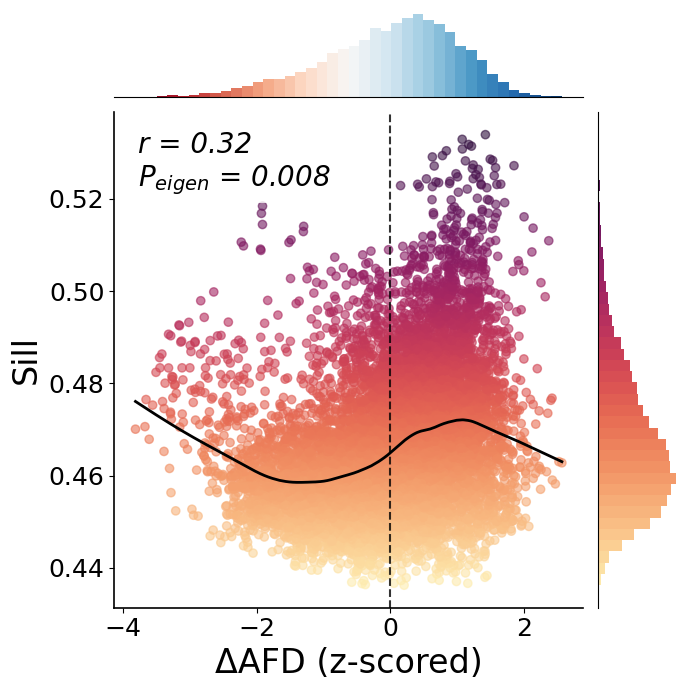

In [195]:
# -------------------------------------------------
# Prepare Data
# -------------------------------------------------
mod1 = copy.deepcopy(dAFD_z)
mod2 = copy.deepcopy(grp_sill_smooth)

valid = ~np.isnan(mod1) & ~np.isnan(mod2)
x = mod1[valid]
y = mod2[valid]

# Spearman correlation
r, p = stats.spearmanr(x, y)

# -------------------------------------------------
# Create JointGrid
# -------------------------------------------------
g = sns.JointGrid(x=x, y=y, height=7, space=0)

# -------------------------------------------------
# Scatter colormap (BASED ON Y)
# -------------------------------------------------
ymin, ymax = np.min(y), np.max(y)

# robust normalization
if ymin < 0 < ymax:
    norm_scatter = mcolors.TwoSlopeNorm(
        vmin=ymin,
        vcenter=0,
        vmax=ymax
    )
else:
    norm_scatter = mcolors.Normalize(
        vmin=ymin,
        vmax=ymax
    )

sc = g.ax_joint.scatter(
    x, y,
    c=y,
    cmap='cmo.matter',
    norm=norm_scatter,
    alpha=0.6
)

# -------------------------------------------------
# LOWESS non-linear fit
# -------------------------------------------------
lowess_fit = lowess(y, x, frac=0.3)

g.ax_joint.plot(
    lowess_fit[:, 0],
    lowess_fit[:, 1],
    color='black',
    linewidth=2
)

g.ax_joint.axvline(
    x=0,
    linestyle='--',
    linewidth=1.5,
    color='black',
    alpha=0.8
)

# -------------------------------------------------
# Marginal Histograms with Colormaps
# -------------------------------------------------

# ---- X histogram (RdBu) ----
counts_x, bins_x = np.histogram(x, bins=40)
centers_x = 0.5 * (bins_x[:-1] + bins_x[1:])

norm_x = mcolors.Normalize(vmin=np.min(x), vmax=np.max(x))
cmap_x = plt.get_cmap("RdBu")

for c, left, right, h in zip(centers_x, bins_x[:-1], bins_x[1:], counts_x):
    g.ax_marg_x.bar(
        left,
        h,
        width=right-left,
        color=cmap_x(norm_x(c)),
        align='edge',
        #edgecolor='black',
        #linewidth=0.6
    )

# ---- Y histogram (matter) ----
counts_y, bins_y = np.histogram(y, bins=40)
centers_y = 0.5 * (bins_y[:-1] + bins_y[1:])

norm_y = mcolors.Normalize(vmin=np.min(y), vmax=np.max(y))
cmap_y = plt.get_cmap("cmo.matter")

for c, bottom, top, w in zip(centers_y, bins_y[:-1], bins_y[1:], counts_y):
    g.ax_marg_y.barh(
        bottom,
        w,
        height=top-bottom,
        color=cmap_y(norm_y(c)),
        align='edge',
        #edgecolor='black',
        #linewidth=0.6
    )

# -------------------------------------------------
# Clean marginal axes
# -------------------------------------------------
g.ax_marg_x.tick_params(bottom=False, labelbottom=False)
g.ax_marg_y.tick_params(left=False, labelleft=False)

# -------------------------------------------------
# Labels
# -------------------------------------------------
g.ax_joint.set_xlabel('ΔAFD (z-scored)', fontsize=24)
g.ax_joint.set_ylabel('Sill', fontsize=24)
g.ax_joint.tick_params(axis='both', labelsize=18)

# p-value formatting
if p < 0.001:
    p_text = "< 0.001"
else:
    p_text = f"= {p:.3f}"

g.ax_joint.text(
    0.05, 0.85,
    f'r = {r:.2f}\n$P_{{eigen}}$ = 0.008',
    #f'r = {r:.2f}\np {p_text}',
    transform=g.ax_joint.transAxes,
    ha='left',
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'),
    fontsize=20,
    fontstyle='italic'
)

# -------------------------------------------------
# Spine thickness
# -------------------------------------------------
for spine in g.ax_joint.spines.values():
    spine.set_linewidth(1.2)

plt.tight_layout()
plt.show()

## Eigen Strapping

In [201]:
from eigenstrapping import datasets, fit, stats
from eigenstrapping.plotting import csplot
from neuromaps.datasets import fetch_atlas
import copy
from nilearn import plotting
from nilearn.plotting.displays import BaseAxes
import matplotlib.pyplot as plt
from matplotlib import gridspec, cm
from neuromaps.datasets import fetch_atlas
from brainspace import mesh as me
#from .utils import is_string_like
#from .geometry import remesh
from eigenstrapping import SurfaceEigenstrapping
from eigenstrapping.geometry import geodesic_distmat

In [202]:
def csplot(scalars, surface='fsLR', hemisphere='left', orientation='landscape', vrange=(-4,4), cmap='viridis'):
    """
    Automated plotting of cortical surfaces. Generates a figure of
    a scalar brainmap `y` and returns `fig` and `ax` handles for
    further use (if needed). Suitable for use with data registered to
    CIFTI 32k space only. Plots data on fs_LR_32k freesurfer-type 
    "midthickness" surface.

    Parameters
    ----------
    scalars : np.ndarray of shape=(32492,)
        Brainmap to visualize registered to standard fs_LR_32k CIFTI space.
    hemisphere : str, optional
        Hemisphere to plot. The default is 'left'.
    orientation : str, optional
        Orientation of plot, 'landscape' or 'portrait'. Default is 'landscape'.
    vrange : tuple, optional
        Maximum range of values to plot. Values higher or lower are truncated.
        Default is (-4, 4).
    cmap : str, optional
        matplotlib.cm color types. The default is 'viridis'.

    Returns
    -------
    fig : matplotlib.figure handle
    ax : matplotlib.ax handle
    
    Notes
    -----
    If there are NaNs present in the brainmap `y`, these are masked out
    of the plotting. See ``nilearn.plotting``

    """
        
    if surface == 'fsaverage':
        surf = 'inflated'
        den = '10k'
    else:
        surf = 'midthickness'
        den = '32k'
        
    # make figure
    if orientation == 'landscape':
        fig = plt.figure(figsize=(9, 6), constrained_layout=False)
        grid = gridspec.GridSpec(1, 2)
        rot = 'vertical'
        axes = [1.01, 0.28, 0.03, 0.4]
    elif orientation == 'portrait':
        fig = plt.figure(figsize=(6, 9), constrained_layout=False)
        grid = gridspec.GridSpec(2, 1)
        rot = 'horizontal'
        axes = [1.01, 0.28, 0.03, 0.4]
        
    if hemisphere == 'left':
        mesh = micapipe + '/surfaces/fsLR-5k.L.surf.gii'
        #bg_map = fetch_atlas(atlas=f'{surface}', density=den)['vaavg'][0]
    elif hemisphere == 'right':
        mesh = micapipe + '/surfaces/fsLR-5k.R.surf.gii'
        #bg_map = fetch_atlas(atlas=f'{surface}', density=den)['vaavg'][1]
    else:
        raise ValueError('Hemisphere can only be "left" or "right"')
    
    # get colormap
    cmap = plt.get_cmap(cmap)
    vmin, vmax = [-3.82, 2.57] #vrange
    view = ['lateral', 'medial']
        
    # plot surface
    for idx in range(2):
        ax = fig.add_subplot(grid[idx], projection='3d')
        plotting.plot_surf(mesh, surf_map=scalars, hemi=hemisphere, view=view[idx], vmin=vmin, vmax=vmax, colorbar=False, cmap=cmap, axes=ax)
        ax.dist = 9
    
    # colorbar
    cax = plt.axes(axes)
    cbar = fig.colorbar(cm.ScalarMappable(norm=None, cmap=cmap), cax=cax, 
                        orientation=rot)
    cbar.set_ticks([])
    cbar.ax.set_title(f'{vmax:.2f}', fontdict={'fontsize':20}, pad=20)
    cbar.ax.set_xlabel(f'{vmin:.2f}', fontdict={'fontsize':20}, labelpad=20)
    
    return fig, ax

### Hemisphere split

In [196]:
mean_T1map = '/host/verges/tank/data/youngeun/myjupyter/array/11subs_mean_T1map.npy'

In [198]:
dAFD_lh = copy.deepcopy(dAFD_z)[:4842]
dAFD_rh = copy.deepcopy(dAFD_z)[4842:]
grp_range_smooth_lh = copy.deepcopy(grp_range_smooth)[:4842]
grp_range_smooth_rh = copy.deepcopy(grp_range_smooth)[4842:]
grp_sill_smooth_lh = copy.deepcopy(grp_sill_smooth)[:4842]
grp_sill_smooth_rh = copy.deepcopy(grp_sill_smooth)[4842:]
T1map_lh = copy.deepcopy(mean_T1map)[:4842]
T1map_rh = copy.deepcopy(mean_T1map)[4842:]

dAFD_lh_masked = dAFD_lh.copy()
dAFD_lh_masked[~valid_lh] = np.nan

surface_lh = '/data_/mica1/01_programs/micapipe-v0.2.0/surfaces/fsLR-5k.L.surf.gii'
surface_rh = '/data_/mica1/01_programs/micapipe-v0.2.0/surfaces/fsLR-5k.R.surf.gii'
mask_L = '/data_/mica1/01_programs/micapipe-v0.2.0/surfaces/fsLR-5k.L.mask.shape.gii'
mask_R = '/data_/mica1/01_programs/micapipe-v0.2.0/surfaces/fsLR-5k.R.mask.shape.gii'

In [41]:
valid_lh = mask_lh.astype(bool)
valid_rh = mask_rh.astype(bool)

(<Figure size 900x600 with 3 Axes>, <Axes3D: >)

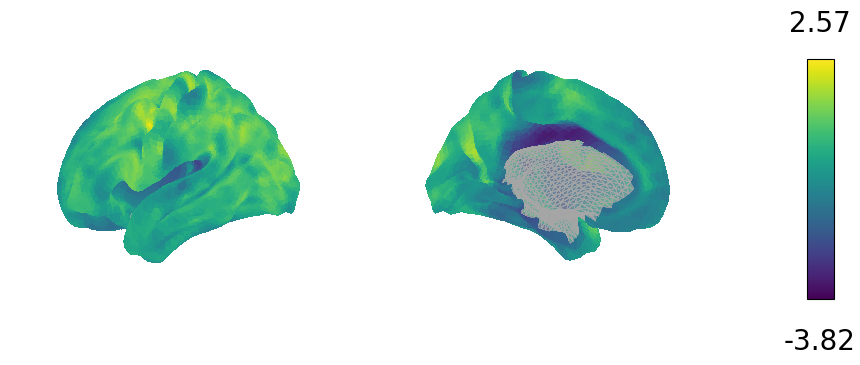

In [23]:
csplot(dAFD_lh, 'fsLR', hemisphere='left')

(<Figure size 900x600 with 3 Axes>, <Axes3D: >)

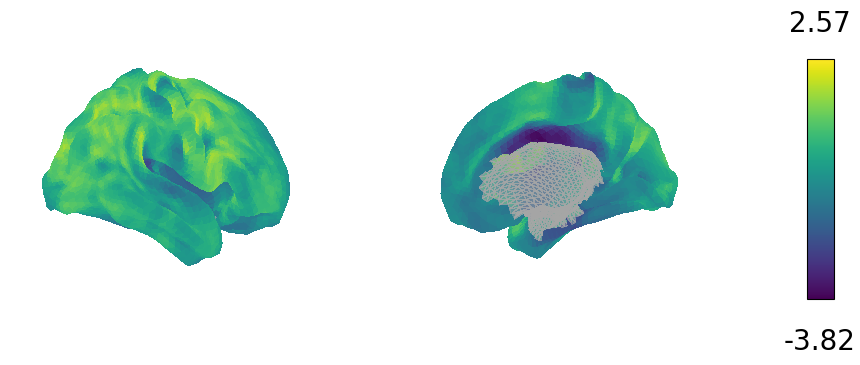

In [24]:
csplot(dAFD_rh, 'fsLR', hemisphere='right')

### Create SurfaceEigenstrapping

In [147]:
eigen_lh = SurfaceEigenstrapping(surface=surface_lh, data=dAFD_lh, num_modes=250, use_cholmod=False)
eigen_rh = SurfaceEigenstrapping(surface=surface_rh, data=dAFD_rh, num_modes=250, use_cholmod=False)
emodes_lh = eigen_lh.emodes
evals_lh = eigen_lh.evals
emodes_rh = eigen_rh.emodes
evals_rh = eigen_rh.evals

Computing eigenmodes on surface using N=250 modes
TriaMesh with regular Laplace-Beltrami
Solver: spsolve (LU decomposition) ...
IMPORTANT: EIGENMODES MUST BE TRUNCATED AT FIRST NON-ZERO MODE FOR THIS FUNCTION TO WORK
Computing eigenmodes on surface using N=250 modes
TriaMesh with regular Laplace-Beltrami
Solver: spsolve (LU decomposition) ...
IMPORTANT: EIGENMODES MUST BE TRUNCATED AT FIRST NON-ZERO MODE FOR THIS FUNCTION TO WORK


In [91]:
distmat_lh = np.loadtxt("/host/verges/tank/data/youngeun/fsLR5k_lh_dist.txt")
distmat_rh = np.loadtxt("/host/verges/tank/data/youngeun/fsLR5k_rh_dist.txt")

In [121]:
index_lh = np.argsort(distmat_lh[np.ix_(valid_lh, valid_lh)], axis=1)
index_rh = np.argsort(distmat_rh[np.ix_(valid_rh, valid_rh)], axis=1)

In [122]:
index_lh = np.argsort(distmat_lh, axis=1)
index_rh = np.argsort(distmat_rh, axis=1)

IMPORTANT: EIGENMODES MUST BE TRUNCATED AT FIRST NON-ZERO MODE FOR THIS FUNCTION TO WORK
Surrogates computed, computing stats...


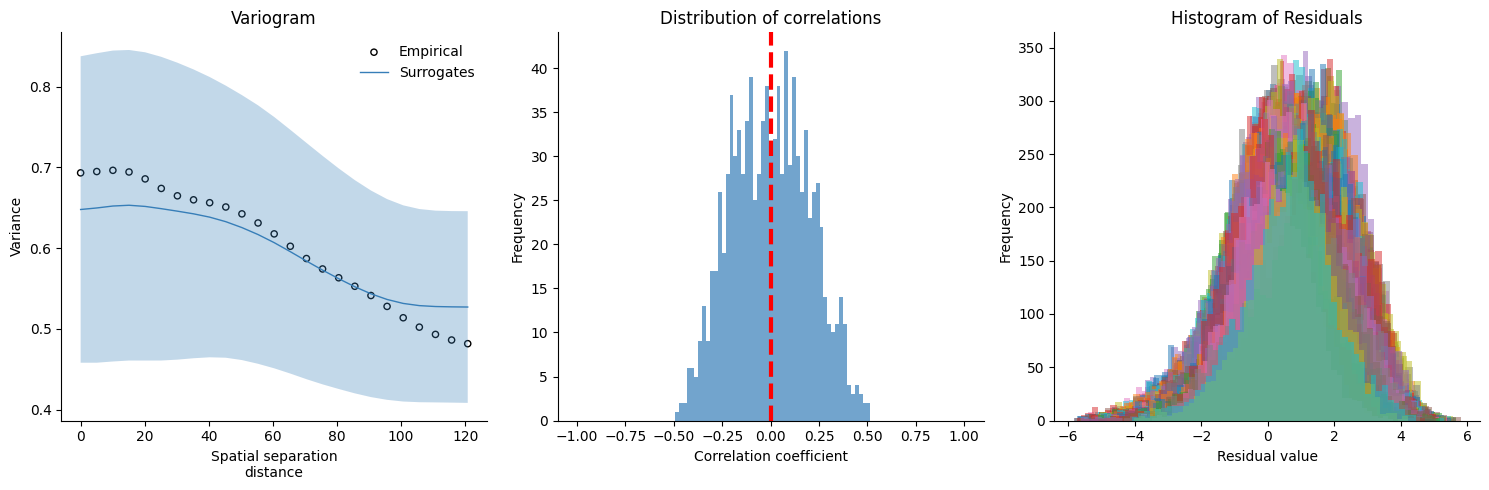

In [165]:
surrs_lh = fit.surface_fit(x=dAFD_lh, D=distmat_lh, emodes=emodes_lh, evals=evals_lh, num_modes=500,
                        index=index_lh, nsurrs=1000, resample=False, return_data=True, surface=surface_lh, extra_diags=True)

IMPORTANT: EIGENMODES MUST BE TRUNCATED AT FIRST NON-ZERO MODE FOR THIS FUNCTION TO WORK
Surrogates computed, computing stats...


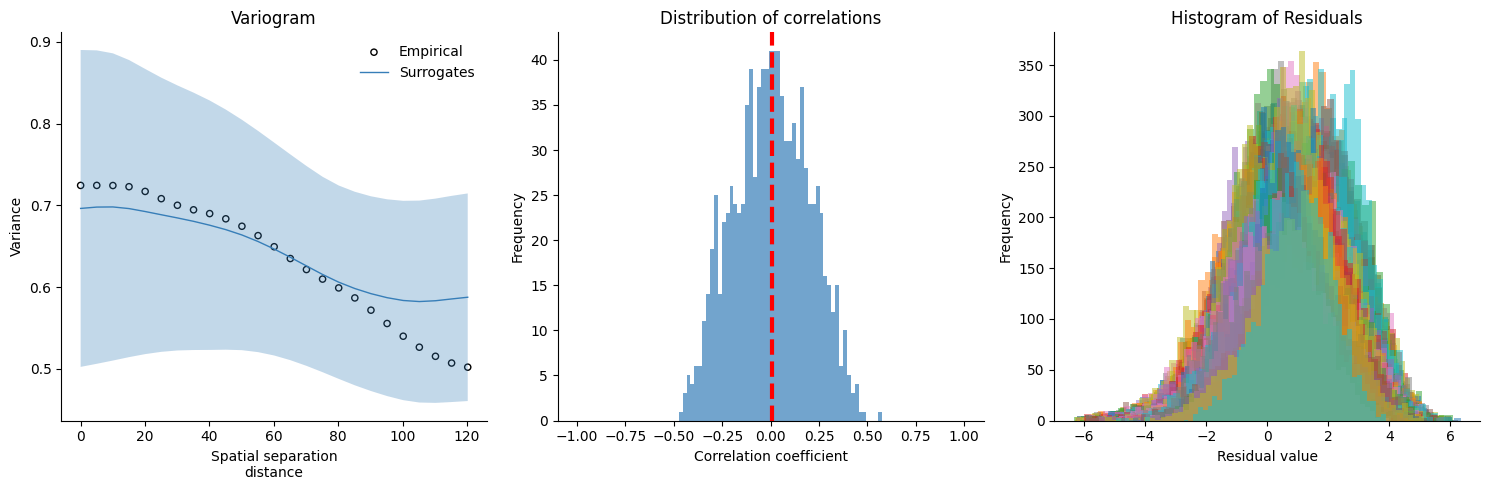

In [166]:
surrs_rh = fit.surface_fit(x=dAFD_rh, D=distmat_rh, emodes=emodes_rh, evals=evals_rh, num_modes=500,
                        index=index_rh, nsurrs=1000, resample=False, return_data=True, surface=surface_rh, extra_diags=True)

In [167]:
corr, pval, perms = stats.compare_maps(dAFD_lh, grp_range_smooth_lh, nulls=surrs_lh, return_nulls=True)

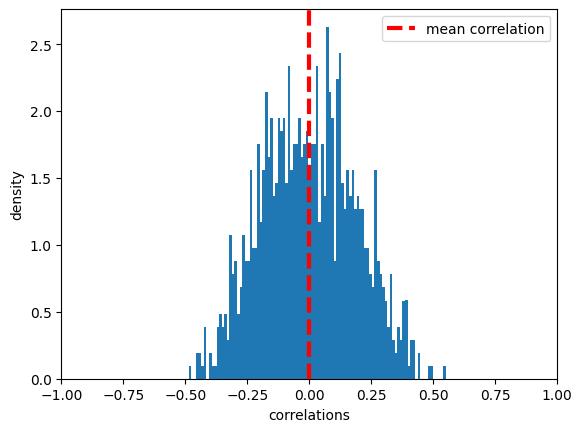

In [168]:
plt.hist(perms, bins=101, density=True)
plt.xlim([-1, 1])
plt.axvline(perms.mean(), linestyle='dashed', zorder=3, lw=3, color='r', label='mean correlation')
plt.xlabel('correlations')
plt.ylabel('density')
plt.legend(loc=0)
plt.show()

In [221]:
surrs_whole = np.concatenate([surrs_lh, surrs_rh], axis=1)

In [235]:
corr, pval, perms = stats.compare_maps(dAFD, grp_range_smooth, nulls=surrs_whole, return_nulls=True)

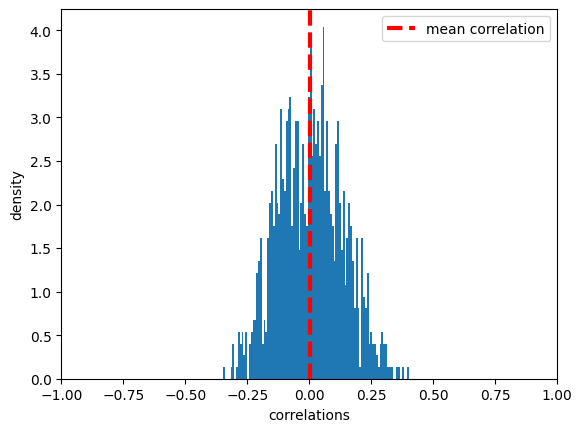

In [236]:
plt.hist(perms, bins=101, density=True)
plt.xlim([-1, 1])
plt.axvline(perms.mean(), linestyle='dashed', zorder=3, lw=3, color='r', label='mean correlation')
plt.xlabel('correlations')
plt.ylabel('density')
plt.legend(loc=0)
plt.show()

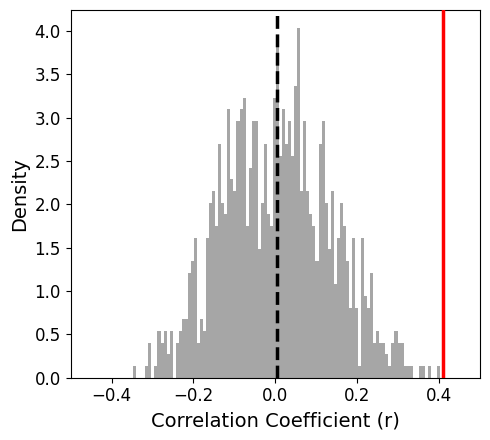

In [237]:
plt.figure(figsize=(5, 4.5))

# histogram (gray bins)
plt.hist(perms, bins=101, density=True, color='gray', alpha=0.7)

# x-axis range
plt.xlim([-0.5, 0.5])

# mean correlation (black dashed line)
plt.axvline(
    perms.mean(),
    linestyle='dashed',
    zorder=3,
    lw=2.5,
    color='black',
    label='mean correlation'
)

# observed correlation (red solid line)
plt.axvline(
    corr,
    linestyle='solid',
    zorder=4,
    lw=2.5,
    color='red',
    label=f'r = {corr:.3f}'
)

plt.xlabel('Correlation Coefficient (r)', fontsize=14)
plt.ylabel('Density', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

#plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

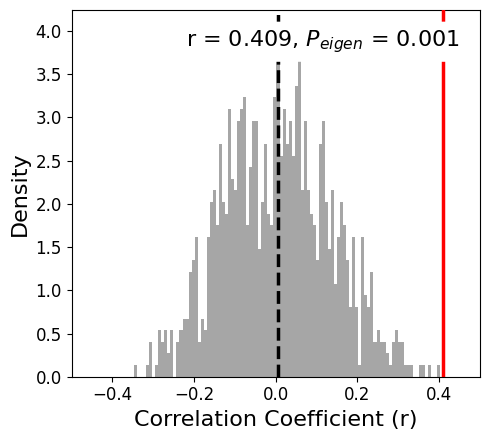

In [241]:
fig, ax = plt.subplots(figsize=(5, 4.5))

# histogram
ax.hist(perms, bins=101, density=True, color='gray', alpha=0.7)

ax.set_xlim([-0.5, 0.5])

# mean correlation
ax.axvline(
    perms.mean(),
    linestyle='dashed',
    zorder=3,
    lw=2.5,
    color='black'
)

# observed correlation
ax.axvline(
    corr,
    linestyle='solid',
    zorder=4,
    lw=2.5,
    color='red'
)

ax.set_xlabel('Correlation Coefficient (r)', fontsize=16)
ax.set_ylabel('Density', fontsize=16)

ax.tick_params(axis='both', labelsize=12)

ax.grid(False)

textstr = f"r = {corr:.3f}, $P_{{eigen}}$ = {pval:.3f}"

ax.text(
    0.95, 0.95,
    textstr,
    zorder=10,
    transform=ax.transAxes,
    fontsize=16,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.3',
              edgecolor='none',
              facecolor='white')
)

plt.tight_layout()
plt.show()

In [183]:
print(f"Observed r = {corr:.3f}")
print(f"p_eigen = {pval:.4f}")

Observed r = 0.409
p_eigen = 0.0010


In [242]:
corr, pval, perms = stats.compare_maps(dAFD, grp_sill_smooth, nulls=surrs_whole, return_nulls=True)

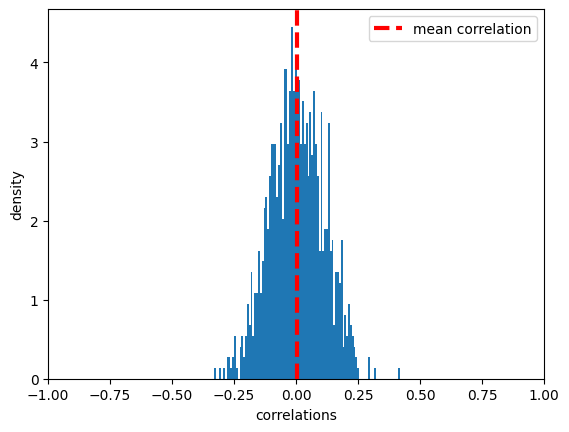

In [243]:
plt.hist(perms, bins=101, density=True)
plt.xlim([-1, 1])
plt.axvline(perms.mean(), linestyle='dashed', zorder=3, lw=3, color='r', label='mean correlation')
plt.xlabel('correlations')
plt.ylabel('density')
plt.legend(loc=0)
plt.show()

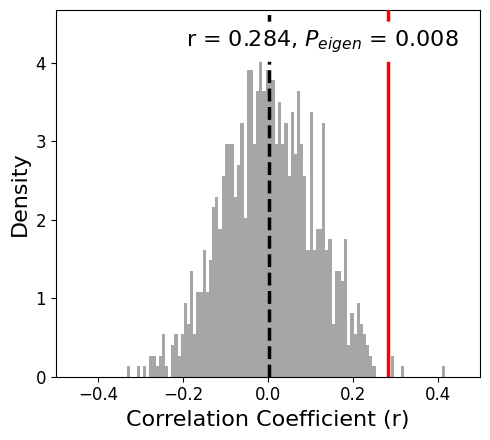

In [244]:
fig, ax = plt.subplots(figsize=(5, 4.5))

# histogram
ax.hist(perms, bins=101, density=True, color='gray', alpha=0.7)

ax.set_xlim([-0.5, 0.5])

# mean correlation
ax.axvline(
    perms.mean(),
    linestyle='dashed',
    zorder=3,
    lw=2.5,
    color='black'
)

# observed correlation
ax.axvline(
    corr,
    linestyle='solid',
    zorder=4,
    lw=2.5,
    color='red'
)

ax.set_xlabel('Correlation Coefficient (r)', fontsize=16)
ax.set_ylabel('Density', fontsize=16)

ax.tick_params(axis='both', labelsize=12)

ax.grid(False)

textstr = f"r = {corr:.3f}, $P_{{eigen}}$ = {pval:.3f}"

ax.text(
    0.95, 0.95,
    textstr,
    zorder=10,
    transform=ax.transAxes,
    fontsize=16,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.3',
              edgecolor='none',
              facecolor='white')
)

plt.tight_layout()
plt.show()

In [186]:
print(f"Observed r = {corr:.3f}")
print(f"p_eigen = {pval:.4f}")

Observed r = 0.284
p_eigen = 0.0080


## Spin Permutation

In [21]:
# Shape of the fsLR-5k matrices
N5k = 9684

# Load spheres fsLR5k
sphere_lh = read_surface(micapipe+'/surfaces/fsLR-5k.L.sphere.surf.gii', itype='gii')
sphere_rh = read_surface(micapipe+'/surfaces/fsLR-5k.R.sphere.surf.gii', itype='gii')

# Let's create some rotations
n_rand = 1000

spinp = SpinPermutations(n_rep=n_rand, random_state=0)
spinp.fit(sphere_lh, points_rh=sphere_rh)

SpinPermutations(n_rep=1000, random_state=0)

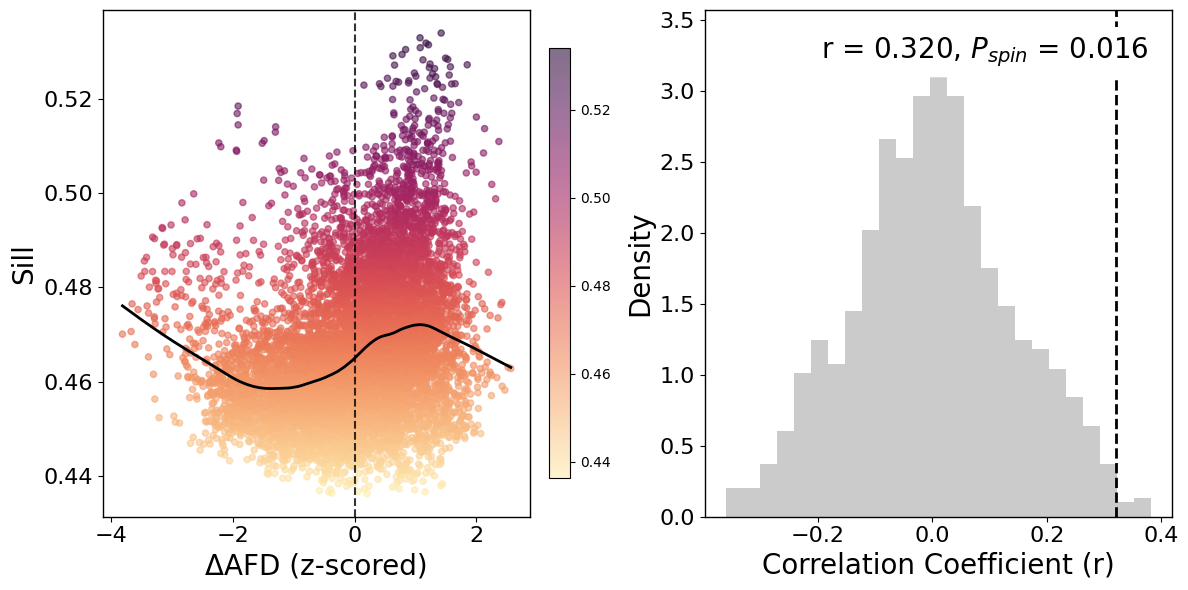

In [22]:
# Load curvature data (left & right hemispheres)
#ffile_path = glob.glob(f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/sub-PNC0{sub_id}/ses-03/func/desc-me_task-rest_bold/surf/*_surf-fsLR-32k_atlas-schaefer-400_desc-FC.shape.gii")[0]
dAFD_11sub = copy.deepcopy(dAFD_z)
dAFD_L = dAFD_11sub[0:int(N5k/2)]
dAFD_R = dAFD_11sub[int(N5k/2):N5k]

# Load SWM intensity profile data
target_variogram = copy.deepcopy(grp_sill_smooth)

# Spin permutation on full data (Get the rotated data)
dAFD_rotated = np.hstack(spinp.randomize(dAFD_L, dAFD_R))
dAFD_rotated_clean = np.nan_to_num(dAFD_rotated)

# Plotting
fig, axs = plt.subplots(1, 2, figsize=(12, 6))  # 1행 2열 서브플롯

mask = ~np.isnan(dAFD_11sub) & ~np.isnan(target_variogram)
non_zero_mask = ~((dAFD_11sub[mask] == 0) & (target_variogram[mask] == 0))
valid_fc = dAFD_11sub[mask][non_zero_mask]
valid_grad = target_variogram[mask][non_zero_mask]

rank_grad = rankdata(valid_grad)

# Observed correlation
r_obs, p_obs = spearmanr(valid_fc, valid_grad)

# Permutation-based correlations
r_spin = np.array([spearmanr(perm[mask][non_zero_mask], valid_grad)[0] for perm in dAFD_rotated_clean])
p_spin = np.mean(np.abs(r_spin) >= np.abs(r_obs))

# =====================================
# LEFT PANEL (axs[0])
# =====================================

mod1 = copy.deepcopy(dAFD_z)
mod2 = copy.deepcopy(grp_sill_smooth)

valid = ~np.isnan(mod1) & ~np.isnan(mod2)

x = mod1[valid]
y = mod2[valid]

# Spearman
r, p = stats.spearmanr(x, y)

# -------------------------------------
# Scatter colormap based on y
# -------------------------------------

ymin, ymax = np.min(y), np.max(y)

if ymin < 0 < ymax:
    norm_scatter = mcolors.TwoSlopeNorm(
        vmin=ymin,
        vcenter=0,
        vmax=ymax
    )
else:
    norm_scatter = mcolors.Normalize(
        vmin=ymin,
        vmax=ymax
    )

sc = axs[0].scatter(x, y, c=y, cmap='cmo.matter', norm=norm_scatter, alpha=0.6, s=20)

# -------------------------------------
# LOWESS
# -------------------------------------

lowess_fit = lowess(y, x, frac=0.3)
axs[0].plot(lowess_fit[:,0], lowess_fit[:,1], color='black', linewidth=2)

# -------------------------------------
# Vertical line
# -------------------------------------

axs[0].axvline(0, linestyle='--', linewidth=1.5, color='black', alpha=0.8)

# -------------------------------------
# Labels
# -------------------------------------

axs[0].set_xlabel('ΔAFD (z-scored)', fontsize=20)
axs[0].set_ylabel('Sill', fontsize=20)
axs[0].tick_params(axis='both', labelsize=16)

# -------------------------------------
# Correlation text
# -------------------------------------

if p < 0.001:
    p_text = "< 0.001"
else:
    p_text = f"= {p:.3f}"

#axs[0].text(0.95, 0.95, f'r = {r:.2f}\np {p_text}', transform=axs[0].transAxes, ha='right', va='top', fontsize=18, fontstyle='italic', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

# optional colorbar
cbar = fig.colorbar(sc, ax=axs[0], fraction=0.046, pad=0.04)
#cbar.set_label('Range', fontsize=16)

# -------------------------------------
# Spine
# -------------------------------------

for spine in axs[0].spines.values():
    spine.set_linewidth(1.2)

axs[0].grid(False)

## Null Distribution Plot
axs[1].hist(r_spin, bins=25, density=True, alpha=0.5, color=(.6, .6, .6))
axs[1].axvline(r_obs, lw=2, ls='--', color='k')
axs[1].set_xlabel(f'Correlation Coefficient (r)', fontsize=20)
axs[1].set_ylabel('Density', fontsize=20)
#axs[1].set_title('Null Distribution', fontsize=16)
axs[1].tick_params(axis='both', which='major', labelsize=16)  # X축, Y축의 눈금 텍스트 크기 설정

axs[1].grid(False)

textstr = f"r = {r_obs:.3f}, $P_{{spin}}$ = {p_spin:.3f}"
axs[1].text(0.95, 0.95, textstr, transform=axs[1].transAxes, fontsize=20,
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round,pad=0.3', edgecolor='none', facecolor='white'))

for ax in axs:
    ax.spines['top'].set_color('black')
    ax.spines['bottom'].set_color('black')
    ax.spines['left'].set_color('black')
    ax.spines['right'].set_color('black')
    
    ax.spines['top'].set_linewidth(1)    # 테두리 두께 조정 (선택 사항)
    ax.spines['bottom'].set_linewidth(1)
    ax.spines['left'].set_linewidth(1)
    ax.spines['right'].set_linewidth(1)

fig.tight_layout()
plt.show()

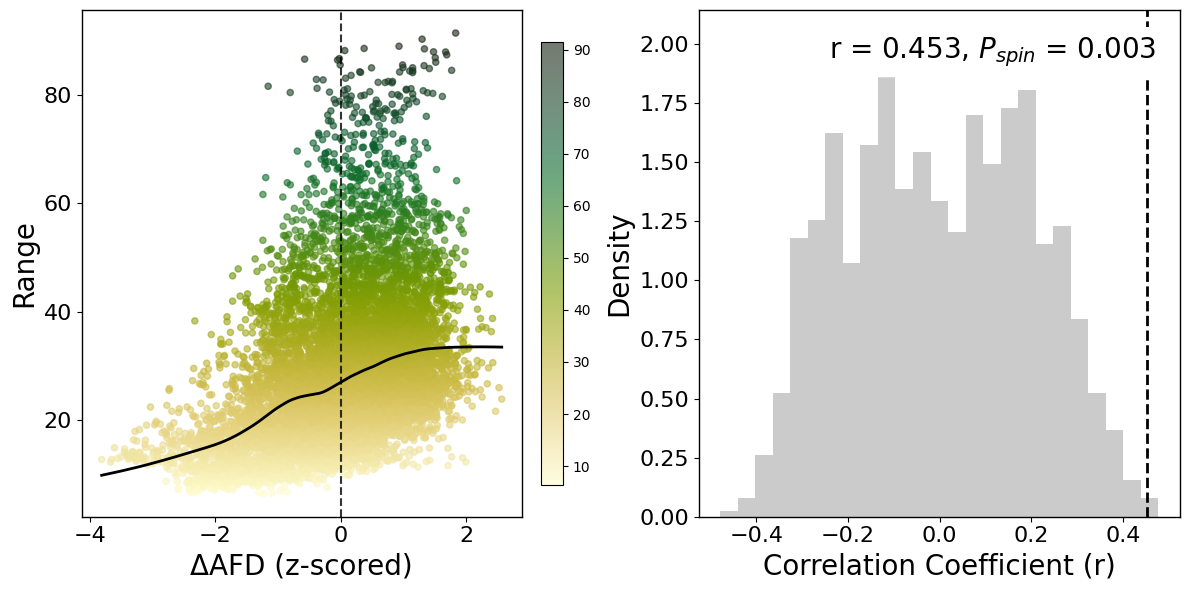

In [23]:
# Load curvature data (left & right hemispheres)
#ffile_path = glob.glob(f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/sub-PNC0{sub_id}/ses-03/func/desc-me_task-rest_bold/surf/*_surf-fsLR-32k_atlas-schaefer-400_desc-FC.shape.gii")[0]
dAFD_11sub = copy.deepcopy(dAFD_z)
dAFD_L = dAFD_11sub[0:int(N5k/2)]
dAFD_R = dAFD_11sub[int(N5k/2):N5k]

# Load SWM intensity profile data
target_variogram = copy.deepcopy(grp_range_smooth)

# Spin permutation on full data (Get the rotated data)
dAFD_rotated = np.hstack(spinp.randomize(dAFD_L, dAFD_R))
dAFD_rotated_clean = np.nan_to_num(dAFD_rotated)

# Plotting
fig, axs = plt.subplots(1, 2, figsize=(12, 6))  # 1행 2열 서브플롯

mask = ~np.isnan(dAFD_11sub) & ~np.isnan(target_variogram)
non_zero_mask = ~((dAFD_11sub[mask] == 0) & (target_variogram[mask] == 0))
valid_fc = dAFD_11sub[mask][non_zero_mask]
valid_grad = target_variogram[mask][non_zero_mask]

rank_grad = rankdata(valid_grad)

# Observed correlation
r_obs, p_obs = spearmanr(valid_fc, valid_grad)

# Permutation-based correlations
r_spin = np.array([spearmanr(perm[mask][non_zero_mask], valid_grad)[0] for perm in dAFD_rotated_clean])
p_spin = np.mean(np.abs(r_spin) >= np.abs(r_obs))

# =====================================
# LEFT PANEL (axs[0])
# =====================================

mod1 = copy.deepcopy(dAFD_z)
mod2 = copy.deepcopy(grp_range_smooth)

valid = ~np.isnan(mod1) & ~np.isnan(mod2)

x = mod1[valid]
y = mod2[valid]

# Spearman
r, p = stats.spearmanr(x, y)

# -------------------------------------
# Scatter colormap based on y
# -------------------------------------

ymin, ymax = np.min(y), np.max(y)

if ymin < 0 < ymax:
    norm_scatter = mcolors.TwoSlopeNorm(
        vmin=ymin,
        vcenter=0,
        vmax=ymax
    )
else:
    norm_scatter = mcolors.Normalize(
        vmin=ymin,
        vmax=ymax
    )

sc = axs[0].scatter(x, y, c=y, cmap='cmo.speed', norm=norm_scatter, alpha=0.6, s=20)

# -------------------------------------
# LOWESS
# -------------------------------------

lowess_fit = lowess(y, x, frac=0.3)
axs[0].plot(lowess_fit[:,0], lowess_fit[:,1], color='black', linewidth=2)

# -------------------------------------
# Vertical line
# -------------------------------------

axs[0].axvline(0, linestyle='--', linewidth=1.5, color='black', alpha=0.8)

# -------------------------------------
# Labels
# -------------------------------------

axs[0].set_xlabel('ΔAFD (z-scored)', fontsize=20)
axs[0].set_ylabel('Range', fontsize=20)
axs[0].tick_params(axis='both', labelsize=16)

# -------------------------------------
# Correlation text
# -------------------------------------

if p < 0.001:
    p_text = "< 0.001"
else:
    p_text = f"= {p:.3f}"

#axs[0].text(0.95, 0.95, f'r = {r:.2f}\np {p_text}', transform=axs[0].transAxes, ha='right', va='top', fontsize=18, fontstyle='italic', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

# optional colorbar
cbar = fig.colorbar(sc, ax=axs[0], fraction=0.046, pad=0.04)
#cbar.set_label('Range', fontsize=16)

# -------------------------------------
# Spine
# -------------------------------------

for spine in axs[0].spines.values():
    spine.set_linewidth(1.2)

axs[0].grid(False)

## Null Distribution Plot
axs[1].hist(r_spin, bins=25, density=True, alpha=0.5, color=(.6, .6, .6))
axs[1].axvline(r_obs, lw=2, ls='--', color='k')
axs[1].set_xlabel(f'Correlation Coefficient (r)', fontsize=20)
axs[1].set_ylabel('Density', fontsize=20)
#axs[1].set_title('Null Distribution', fontsize=16)
axs[1].tick_params(axis='both', which='major', labelsize=16)  # X축, Y축의 눈금 텍스트 크기 설정

axs[1].grid(False)

textstr = f"r = {r_obs:.3f}, $P_{{spin}}$ = {p_spin:.3f}"
axs[1].text(0.95, 0.95, textstr, transform=axs[1].transAxes, fontsize=20,
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round,pad=0.3', edgecolor='none', facecolor='white'))

for ax in axs:
    ax.spines['top'].set_color('black')
    ax.spines['bottom'].set_color('black')
    ax.spines['left'].set_color('black')
    ax.spines['right'].set_color('black')
    
    ax.spines['top'].set_linewidth(1)    # 테두리 두께 조정 (선택 사항)
    ax.spines['bottom'].set_linewidth(1)
    ax.spines['left'].set_linewidth(1)
    ax.spines['right'].set_linewidth(1)

fig.tight_layout()
plt.show()

## 17 Yeo Networks

In [77]:
from brainstat.datasets import fetch_yeo_networks_metadata
from brainstat.datasets import fetch_parcellation

yeo_14networks = fetch_parcellation("fsaverage5", "yeo", 17)
network_names, yeo_colormap = fetch_yeo_networks_metadata(17)

In [78]:
left = yeo_14networks[:len(yeo_14networks)//2]
right = yeo_14networks[len(yeo_14networks)//2:]

In [9]:
imgL = nb.gifti.GiftiImage()
imgR = nb.gifti.GiftiImage()
img = nb.gifti.GiftiImage()

dataL = nb.gifti.GiftiDataArray(left.astype(np.int32))
dataR = nb.gifti.GiftiDataArray(right.astype(np.int32))
data = nb.gifti.GiftiDataArray(yeo_14networks.astype(np.int32))

imgL.add_gifti_data_array(dataL)
imgR.add_gifti_data_array(dataR)
img.add_gifti_data_array(data)

In [104]:
nb.save(imgL, '/host/verges/tank/data/youngeun/parcellations/lh.Yeo2011_17Networks_fsaverage5.shape.gii')
nb.save(imgR, '/host/verges/tank/data/youngeun/parcellations/rh.Yeo2011_17Networks_fsaverage5.shape.gii')

In [52]:
fsLR_5k_L =  nb.load('/host/verges/tank/data/youngeun/parcellations/lh.Yeo2011_17Networks_fsLR5k.shape.gii').darrays[0].data
fsLR_5k_R =  nb.load('/host/verges/tank/data/youngeun/parcellations/rh.Yeo2011_17Networks_fsLR5k.shape.gii').darrays[0].data

In [53]:
round_fsLR_5k_L = np.round(fsLR_5k_L).astype(float)
round_fsLR_5k_R = np.round(fsLR_5k_R).astype(float)
fsLR_5k_17yeo = np.concatenate((round_fsLR_5k_L, round_fsLR_5k_R), axis=0)

In [54]:
fsLR_5k_17yeo[mask_5k == False] = np.nan

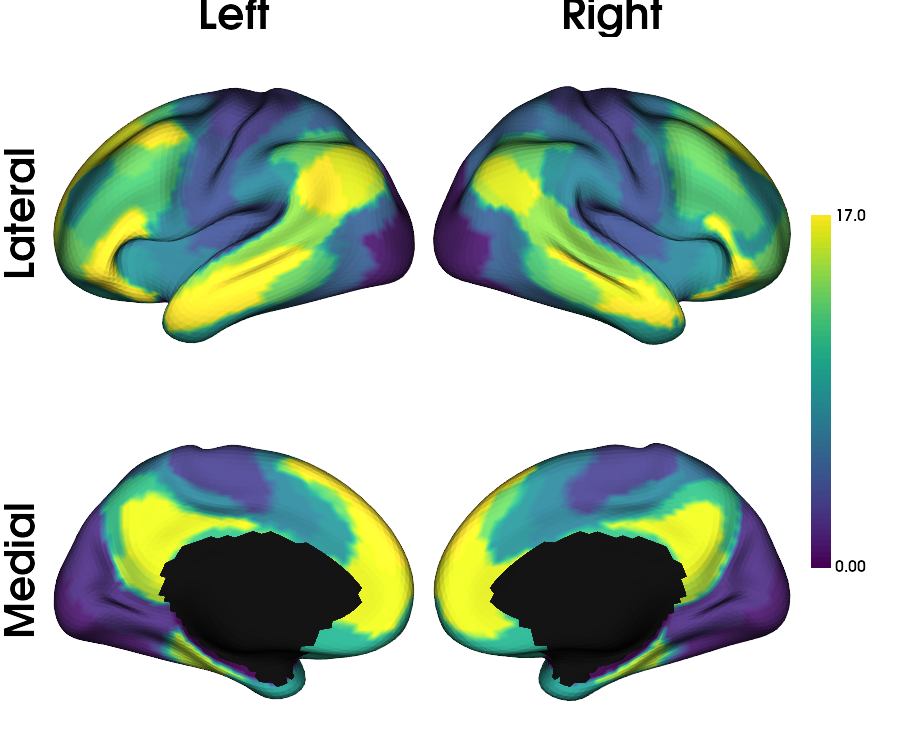

In [55]:
plot_hemispheres(inf_lh, inf_rh, array_name=fsLR_5k_17yeo, cmap='viridis', nan_color=(0, 0, 0, 1),
                              zoom=1.3, size=(900, 750), embed_nb=True,
                              color_bar='right', layout_style='grid', 
                              label_text={'left': ['Lateral', 'Medial'], 'top': ['Left', 'Right']},
                              screenshot=False)

## 7 Yeo Networks

In [18]:
fsLR_5k_L =  nb.load('/host/verges/tank/data/youngeun/parcellations/lh.Yeo2011_7Networks_fsLR5k.shape.gii').darrays[0].data
fsLR_5k_R =  nb.load('/host/verges/tank/data/youngeun/parcellations/rh.Yeo2011_7Networks_fsLR5k.shape.gii').darrays[0].data

In [19]:
round_fsLR_5k_L = np.round(fsLR_5k_L).astype(int)
round_fsLR_5k_R = np.round(fsLR_5k_R).astype(int)
fsLR_5k_yeo = np.concatenate((round_fsLR_5k_L, round_fsLR_5k_R), axis=0)

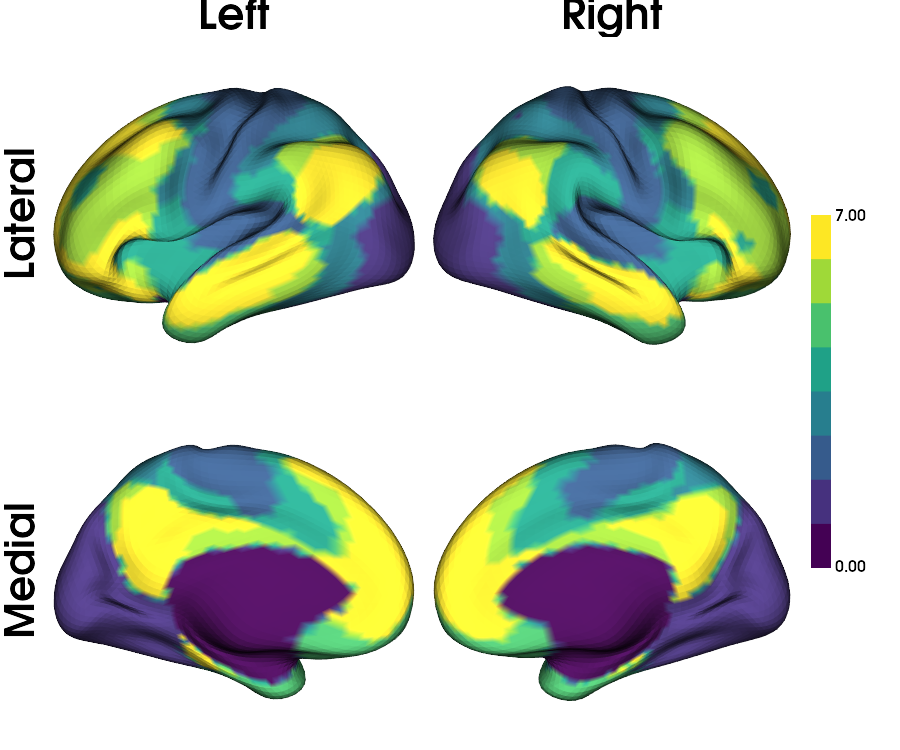

In [20]:
plot_hemispheres(inf_lh, inf_rh, array_name=fsLR_5k_yeo, cmap='viridis', nan_color=(0, 0, 0, 1),
                              zoom=1.3, size=(900, 750), embed_nb=True,
                              color_bar='right', layout_style='grid', 
                              label_text={'left': ['Lateral', 'Medial'], 'top': ['Left', 'Right']},
                              screenshot=False)

In [151]:
import numpy as np

net_labels = np.unique(fsLR_5k_yeo)
net_labels = net_labels[~np.isnan(net_labels)]

n_vert_l = len(fsLR_5k_yeo) // 2
yeo_l = fsLR_5k_yeo[:n_vert_l]
yeo_r = fsLR_5k_yeo[n_vert_l:]


def print_net_stats(yeo, grp_sill, grp_range, hemi):

    print(f"\n=== {hemi} Hemisphere ===\n")

    for net in np.unique(yeo):
        if np.isnan(net):
            continue

        mask = (yeo == net)

        sill_vals  = grp_sill[mask]
        range_vals = grp_range[mask]

        sill_mean = np.nanmean(sill_vals)
        sill_std  = np.nanstd(sill_vals)

        range_mean = np.nanmean(range_vals)
        range_std  = np.nanstd(range_vals)

        print(
            f"Network {int(net):2d}: "
            f"SILL = {sill_mean:.4f} ± {sill_std:.4f} | "
            f"RANGE = {range_mean:.4f} ± {range_std:.4f}"
        )


# LEFT
print_net_stats(
    yeo_l,
    grp_sill_smooth[:n_vert_l],
    grp_range_smooth[:n_vert_l],
    "LEFT"
)

# RIGHT
print_net_stats(
    yeo_r,
    grp_sill_smooth[n_vert_l:],
    grp_range_smooth[n_vert_l:],
    "RIGHT"
)


=== LEFT Hemisphere ===

Network  0: SILL = 0.4578 ± 0.0027 | RANGE = 9.5494 ± 1.4640
Network  1: SILL = 0.4648 ± 0.0120 | RANGE = 40.3517 ± 19.7696
Network  2: SILL = 0.4597 ± 0.0106 | RANGE = 32.1401 ± 14.4567
Network  3: SILL = 0.4690 ± 0.0116 | RANGE = 32.2133 ± 12.7205
Network  4: SILL = 0.4653 ± 0.0116 | RANGE = 22.3297 ± 7.0277
Network  5: SILL = 0.4611 ± 0.0092 | RANGE = 17.3495 ± 8.0823
Network  6: SILL = 0.4814 ± 0.0152 | RANGE = 31.5844 ± 11.4813
Network  7: SILL = 0.4769 ± 0.0189 | RANGE = 29.3112 ± 10.0178

=== RIGHT Hemisphere ===

Network  0: SILL = 0.4574 ± 0.0034 | RANGE = 7.9428 ± 2.0820
Network  1: SILL = 0.4579 ± 0.0103 | RANGE = 40.8041 ± 19.9388
Network  2: SILL = 0.4577 ± 0.0112 | RANGE = 28.5302 ± 12.1186
Network  3: SILL = 0.4650 ± 0.0105 | RANGE = 28.3999 ± 9.5372
Network  4: SILL = 0.4633 ± 0.0106 | RANGE = 22.0399 ± 6.7793
Network  5: SILL = 0.4628 ± 0.0083 | RANGE = 14.9013 ± 7.5159
Network  6: SILL = 0.4819 ± 0.0149 | RANGE = 28.1070 ± 8.4494
Network  7: 

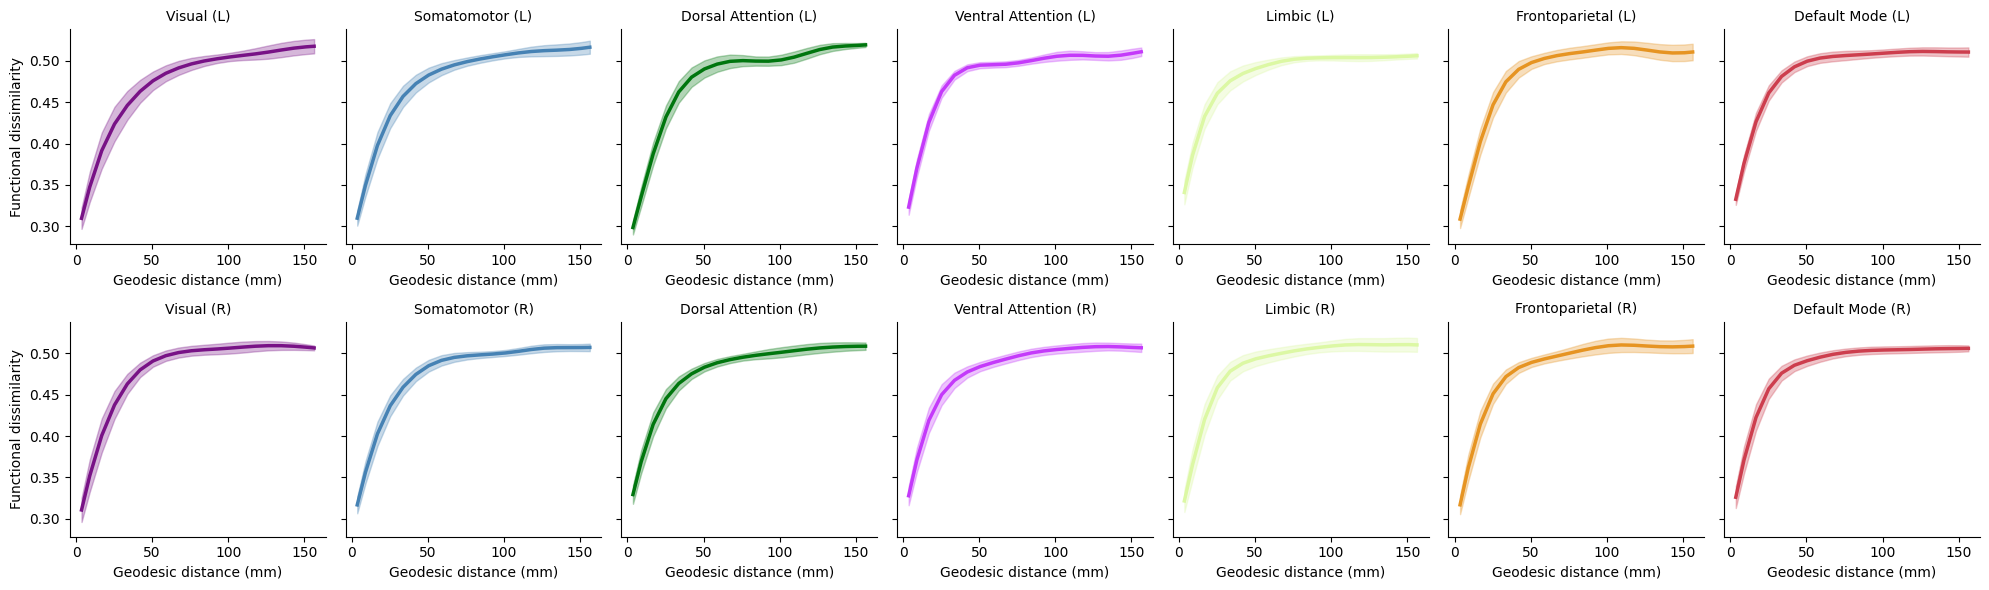

In [152]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# Parameters
# ---------------------------------------------------
clipStart = 0
clipEnd   = 150

# ---------------------------------------------------
# Network labels & colors
# ---------------------------------------------------
net_names = {
    1: "Visual",
    2: "Somatomotor",
    3: "Dorsal Attention",
    4: "Ventral Attention",
    5: "Limbic",
    6: "Frontoparietal",
    7: "Default Mode"
}

net_colors = {
    1: (120/255, 18/255, 134/255),
    2: (70/255, 130/255, 180/255),
    3: (0/255, 118/255, 14/255),
    4: (196/255, 58/255, 250/255),
    5: (220/255, 248/255, 164/255),
    6: (230/255, 148/255, 34/255),
    7: (205/255, 62/255, 78/255),
}

# ---------------------------------------------------
# Hemisphere-specific Yeo labels
# ---------------------------------------------------
n_vert_l = ind_fc_hVw_l.shape[1]
n_vert_r = ind_fc_hVw_r.shape[1]

yeo_l = fsLR_5k_yeo[:n_vert_l]
yeo_r = fsLR_5k_yeo[n_vert_l:n_vert_l+n_vert_r]

# ---------------------------------------------------
# Store results
# ---------------------------------------------------
net_results = []

# ===================================================
# LEFT hemisphere
# ===================================================
for net in range(1, 8):

    net_idx = np.where(yeo_l == net)[0]

    if len(net_idx) == 0:
        continue

    h_net = ind_fc_hVw_l[:, net_idx, clipStart:clipEnd]
    v_net = ind_fc_evVw_l[:, net_idx, clipStart:clipEnd]

    # average across vertices within each subject
    h_sub = np.nanmean(h_net, axis=1)
    v_sub = np.nanmean(v_net, axis=1)
    
    # remove invalid subjects
    valid = (~np.isnan(h_sub).any(axis=1) & ~np.isnan(v_sub).any(axis=1))
    
    h_sub = h_sub[valid]
    v_sub = v_sub[valid]
    
    # group mean ± subject SD
    mu_h = np.nanmean(h_sub, axis=0)
    mu_h = gaussian_filter1d(mu_h, sigma=1)
    mu_v = np.nanmean(v_sub, axis=0)
    mu_v = gaussian_filter1d(mu_v, sigma=1)
    sd_v = np.nanstd(v_sub, axis=0)
    sd_v = gaussian_filter1d(sd_v, sigma=1)

    sill_net  = np.nanmean(sill_ind_l[:, net_idx])
    range_net = np.nanmean(range_ind_l[:, net_idx])

    net_results.append({
        "hemi": "L",
        "net": net,
        "h": mu_h,
        "mu_s": mu_v,
        "sigma_s": sd_v,
        "sill": sill_net,
        "range": range_net
    })


# ===================================================
# RIGHT hemisphere
# ===================================================
for net in range(1, 8):

    net_idx = np.where(yeo_r == net)[0]

    if len(net_idx) == 0:
        continue

    h_net = ind_fc_hVw_r[:, net_idx, clipStart:clipEnd]
    v_net = ind_fc_evVw_r[:, net_idx, clipStart:clipEnd]

    # average across vertices within each subject
    h_sub = np.nanmean(h_net, axis=1)
    v_sub = np.nanmean(v_net, axis=1)
    
    # remove invalid subjects
    valid = (
        ~np.isnan(h_sub).any(axis=1) &
        ~np.isnan(v_sub).any(axis=1)
    )
    
    h_sub = h_sub[valid]
    v_sub = v_sub[valid]
    
    # group mean ± subject SD
    mu_h = np.nanmean(h_sub, axis=0)
    mu_h = gaussian_filter1d(mu_h, sigma=1)
    mu_v = np.nanmean(v_sub, axis=0)
    mu_v = gaussian_filter1d(mu_v, sigma=1)
    sd_v = np.nanstd(v_sub, axis=0)
    sd_v = gaussian_filter1d(sd_v, sigma=1)

    sill_net  = np.nanmean(sill_ind_r[:, net_idx])
    range_net = np.nanmean(range_ind_r[:, net_idx])

    net_results.append({
        "hemi": "R",
        "net": net,
        "h": mu_h,
        "mu_s": mu_v,
        "sigma_s": sd_v,
        "sill": sill_net,
        "range": range_net
    })


# ===================================================
# Plot
# ===================================================
fig, axs = plt.subplots(2, 7, figsize=(20, 6), sharey=True)

for res in net_results:

    row = 0 if res["hemi"] == "L" else 1
    col = res["net"] - 1

    ax = axs[row, col]

    x = res["h"]
    mu_s = res["mu_s"]
    sigma_s = res["sigma_s"]

    color = net_colors[res["net"]]

    # -----------------------------------
    # Mean ± SD
    # -----------------------------------
    ax.fill_between(
        x,
        mu_s - sigma_s,
        mu_s + sigma_s,
        color=color,
        alpha=0.3
    )

    ax.plot(
        x,
        mu_s,
        lw=2.5,
        color=color
    )

    # -----------------------------------
    # Sill / Range
    # -----------------------------------
    #ax.axhline(res["sill"], ls='--', lw=1.5, color='k', alpha=0.8)
    #ax.axvline(res["range"], ls='--', lw=1.5, color='k', alpha=0.8)

    # -----------------------------------
    # Formatting
    # -----------------------------------
    ax.set_title(
        f"{net_names[res['net']]} ({res['hemi']})",
        fontsize=10
    )

    ax.set_xlabel("Geodesic distance (mm)")

    if col == 0:
        ax.set_ylabel("Functional dissimilarity")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### only 95% from the distribution

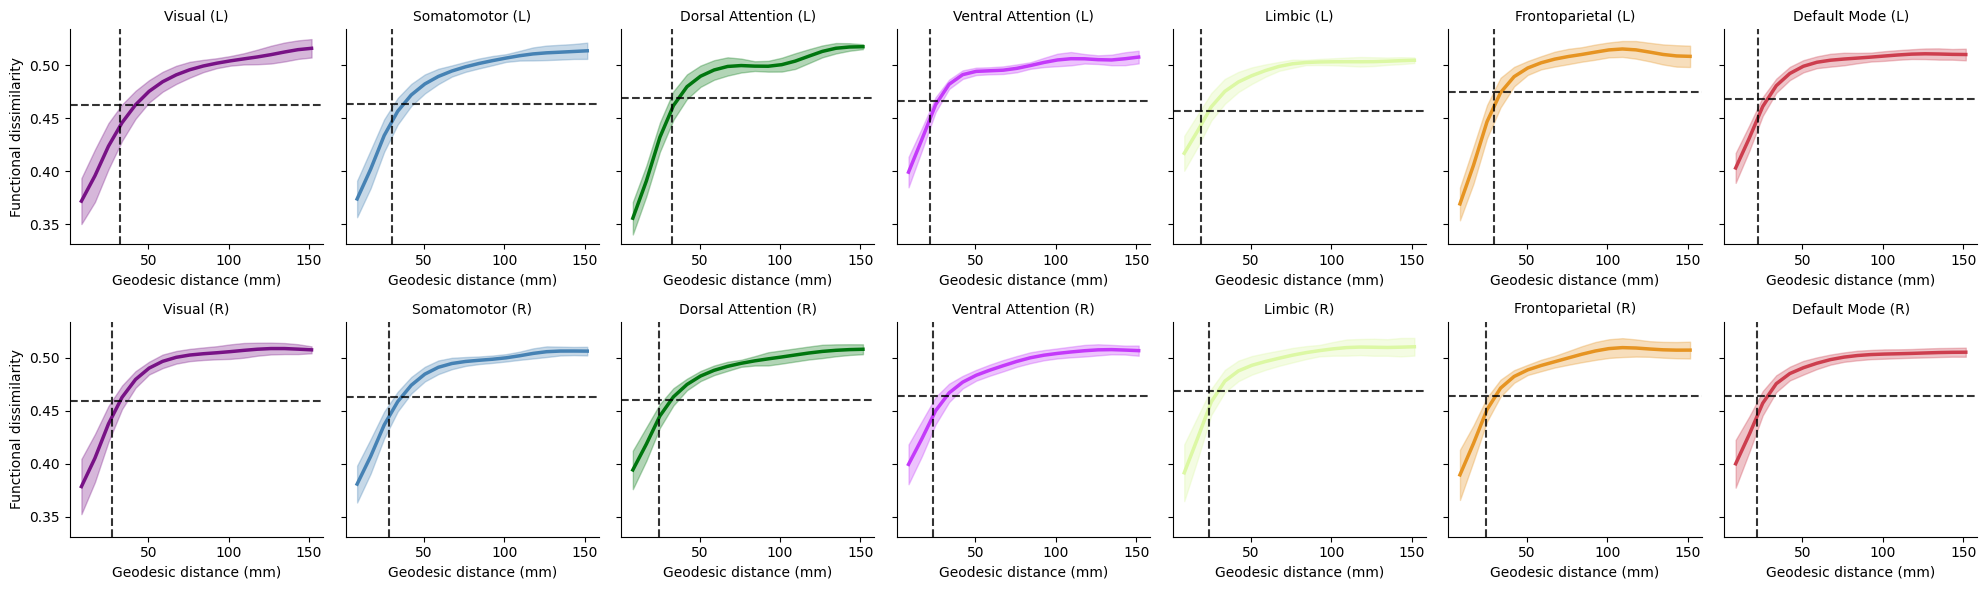

In [153]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# Parameters
# ---------------------------------------------------
clipStart = 1
clipEnd   = 19


# ---------------------------------------------------
# Network labels & colors
# ---------------------------------------------------
net_names = {
    1: "Visual",
    2: "Somatomotor",
    3: "Dorsal Attention",
    4: "Ventral Attention",
    5: "Limbic",
    6: "Frontoparietal",
    7: "Default Mode"
}

net_colors = {
    1: (120/255, 18/255, 134/255),
    2: (70/255, 130/255, 180/255),
    3: (0/255, 118/255, 14/255),
    4: (196/255, 58/255, 250/255),
    5: (220/255, 248/255, 164/255),
    6: (230/255, 148/255, 34/255),
    7: (205/255, 62/255, 78/255),
}


# ---------------------------------------------------
# Robust trimming function (95% central distribution)
# ---------------------------------------------------
def trim_95(x):
    x = x[np.isfinite(x)]
    low, high = np.nanpercentile(x, [5, 95])
    return x[(x >= low) & (x <= high)]


# ---------------------------------------------------
# Store results
# ---------------------------------------------------
net_results = []


# ===================================================
# LEFT hemisphere
# ===================================================
for net in range(1, 8):

    net_idx = np.where(yeo_l == net)[0]

    if len(net_idx) == 0:
        continue

    # ------------------------------------------------
    # Variogram extraction (NO vertex removal)
    # ------------------------------------------------
    h_net = ind_fc_hVw_l[:, net_idx, clipStart:clipEnd]
    v_net = ind_fc_evVw_l[:, net_idx, clipStart:clipEnd]

    h_sub = np.nanmean(h_net, axis=1)
    v_sub = np.nanmean(v_net, axis=1)

    valid = (
        ~np.isnan(h_sub).any(axis=1) &
        ~np.isnan(v_sub).any(axis=1)
    )

    h_sub = h_sub[valid]
    v_sub = v_sub[valid]

    mu_h = np.nanmean(h_sub, axis=0)
    mu_v = np.nanmean(v_sub, axis=0)
    mu_v = gaussian_filter1d(mu_v, sigma=1)
    sd_v = np.nanstd(v_sub, axis=0)

    # ------------------------------------------------
    # SILL / RANGE distribution (ROBUST ESTIMATION)
    # ------------------------------------------------
    sill_vals  = sill_ind_l[:, net_idx].flatten()
    range_vals = range_ind_l[:, net_idx].flatten()

    sill_vals_trim  = trim_95(sill_vals)
    range_vals_trim = trim_95(range_vals)

    sill_net  = np.nanmean(sill_vals_trim)
    range_net = np.nanmean(range_vals_trim)

    net_results.append({
        "hemi": "L",
        "net": net,
        "h": mu_h,
        "mu_s": mu_v,
        "sigma_s": sd_v,
        "sill": sill_net,
        "range": range_net
    })


# ===================================================
# RIGHT hemisphere
# ===================================================
for net in range(1, 8):

    net_idx = np.where(yeo_r == net)[0]

    if len(net_idx) == 0:
        continue

    h_net = ind_fc_hVw_r[:, net_idx, clipStart:clipEnd]
    v_net = ind_fc_evVw_r[:, net_idx, clipStart:clipEnd]

    h_sub = np.nanmean(h_net, axis=1)
    v_sub = np.nanmean(v_net, axis=1)

    valid = (
        ~np.isnan(h_sub).any(axis=1) &
        ~np.isnan(v_sub).any(axis=1)
    )

    h_sub = h_sub[valid]
    v_sub = v_sub[valid]
    #v_sub = v_sub - v_sub[:, [0]]
    mu_h = np.nanmean(h_sub, axis=0)
    mu_v = np.nanmean(v_sub, axis=0)
    mu_v = gaussian_filter1d(mu_v, sigma=1)
    sd_v = np.nanstd(v_sub, axis=0)

    sill_vals  = sill_ind_r[:, net_idx].flatten()
    range_vals = range_ind_r[:, net_idx].flatten()

    sill_vals_trim  = trim_95(sill_vals)
    range_vals_trim = trim_95(range_vals)

    sill_net  = np.nanmean(sill_vals_trim)
    range_net = np.nanmean(range_vals_trim)

    net_results.append({
        "hemi": "R",
        "net": net,
        "h": mu_h,
        "mu_s": mu_v,
        "sigma_s": sd_v,
        "sill": sill_net,
        "range": range_net
    })


# ===================================================
# PLOT
# ===================================================
fig, axs = plt.subplots(2, 7, figsize=(20, 6), sharey=True)

for res in net_results:

    row = 0 if res["hemi"] == "L" else 1
    col = res["net"] - 1

    ax = axs[row, col]

    x = res["h"]
    mu = res["mu_s"]
    sd = res["sigma_s"]

    color = net_colors[res["net"]]

    # -----------------------------
    # Mean ± SD
    # -----------------------------
    ax.fill_between(
        x,
        mu - sd,
        mu + sd,
        color=color,
        alpha=0.3
    )

    ax.plot(x, mu, lw=2.5, color=color)

    # -----------------------------
    # SILL (horizontal)
    # -----------------------------
    ax.axhline(
        res["sill"],
        ls='--',
        lw=1.5,
        color='k',
        alpha=0.8
    )

    # -----------------------------
    # RANGE (vertical)
    # -----------------------------
    ax.axvline(
        res["range"],
        ls='--',
        lw=1.5,
        color='k',
        alpha=0.8
    )

    # -----------------------------
    # Formatting
    # -----------------------------
    ax.set_title(
        f"{net_names[res['net']]} ({res['hemi']})",
        fontsize=10
    )

    ax.set_xlabel("Geodesic distance (mm)")

    if col == 0:
        ax.set_ylabel("Functional dissimilarity")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

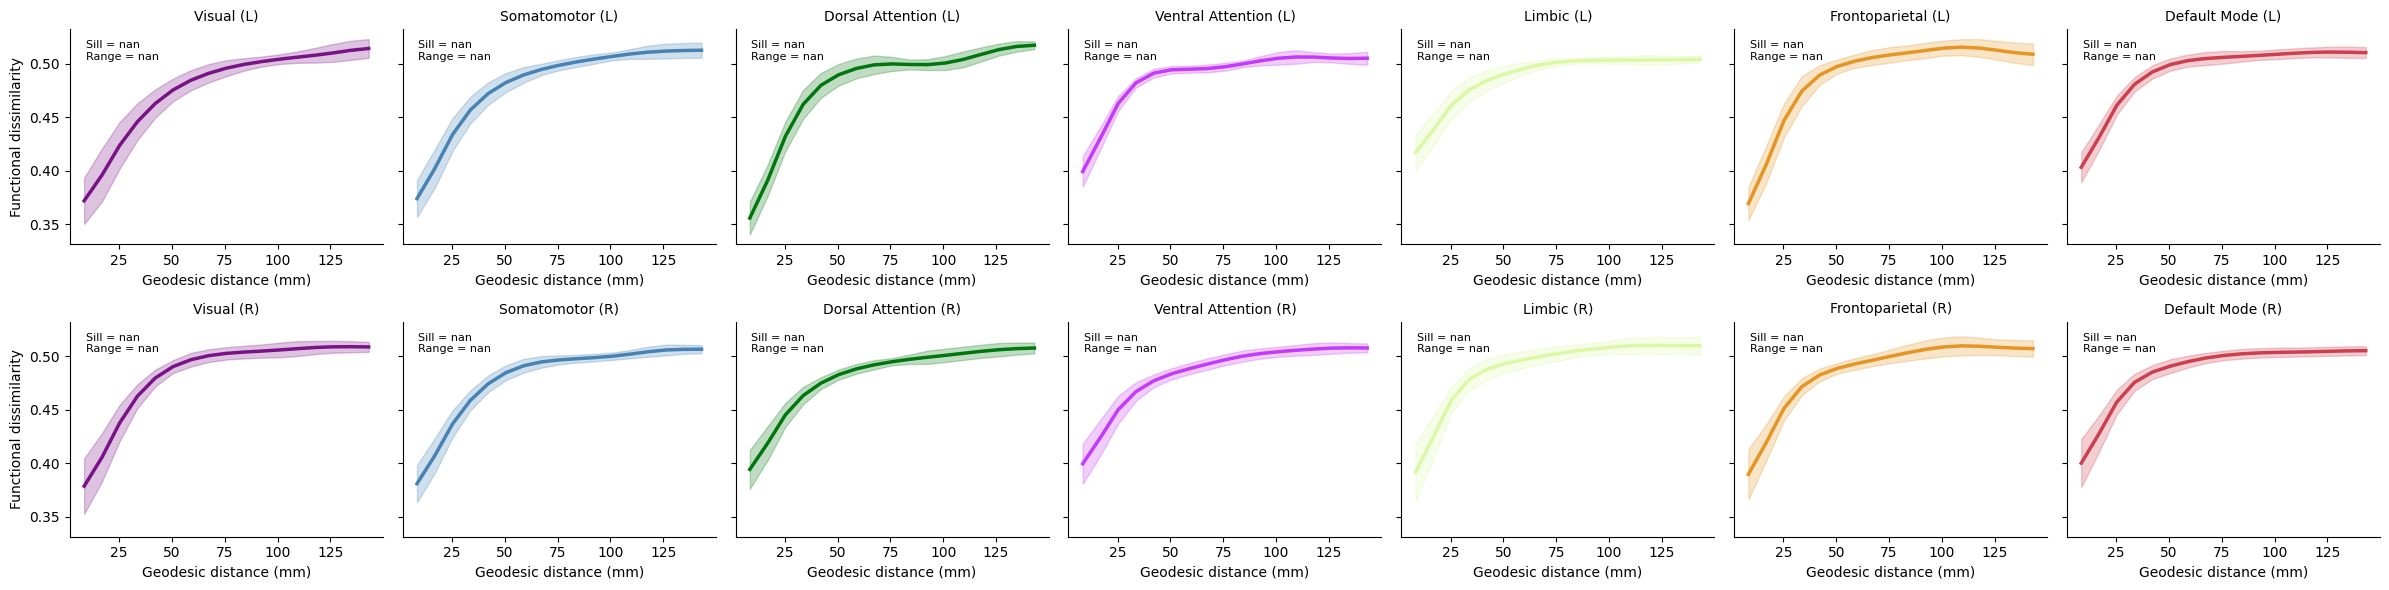

In [64]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d

# ===================================================
# Parameters
# ===================================================
clipStart = 1
clipEnd   = 18


# ===================================================
# Exponential variogram model
# no nugget
# always starts at (0,0)
# ===================================================
def exponential_no_nugget(h, r, sill):

    return nugget + sill * (1 - np.exp(-h / (r / 3)))


# ===================================================
# Network labels & colors
# ===================================================
net_names = {
    1: "Visual",
    2: "Somatomotor",
    3: "Dorsal Attention",
    4: "Ventral Attention",
    5: "Limbic",
    6: "Frontoparietal",
    7: "Default Mode"
}

net_colors = {
    1: (120/255, 18/255, 134/255),
    2: (70/255, 130/255, 180/255),
    3: (0/255, 118/255, 14/255),
    4: (196/255, 58/255, 250/255),
    5: (220/255, 248/255, 164/255),
    6: (230/255, 148/255, 34/255),
    7: (205/255, 62/255, 78/255),
}


# ===================================================
# Hemisphere-specific Yeo labels
# ===================================================
n_vert_l = ind_fc_hVw_l.shape[1]
n_vert_r = ind_fc_hVw_r.shape[1]

yeo_l = fsLR_5k_yeo[:n_vert_l]
yeo_r = fsLR_5k_yeo[n_vert_l:n_vert_l+n_vert_r]


# ===================================================
# Store results
# ===================================================
net_results = []


# ===================================================
# Function
# ===================================================
def process_network_variogram(
    h_data,
    v_data,
    yeo_labels,
    hemi_label
):

    results = []

    for net in range(1, 8):

        net_idx = np.where(yeo_labels == net)[0]

        if len(net_idx) == 0:
            continue

        # -----------------------------------
        # empirical variogram
        # -----------------------------------
        h_net = h_data[:, net_idx, clipStart:clipEnd]
        v_net = v_data[:, net_idx, clipStart:clipEnd]

        # average across vertices
        h_sub = np.nanmean(h_net, axis=1)
        v_sub = np.nanmean(v_net, axis=1)

        # remove bad subjects
        valid = (
            ~np.isnan(h_sub).any(axis=1) &
            ~np.isnan(v_sub).any(axis=1)
        )

        h_sub = h_sub[valid]
        v_sub = v_sub[valid]

        # -----------------------------------
        # group-average variogram
        # -----------------------------------
        mu_h = np.nanmean(h_sub, axis=0)
        mu_v = np.nanmean(v_sub, axis=0)

        # shift to start at 0
        #mu_v = mu_v - mu_v[0]

        # smoothing
        mu_v = gaussian_filter1d(mu_v, sigma=1)

        # SD across subjects
        sd_v = np.nanstd(v_sub, axis=0)

        # -----------------------------------
        # force origin for fitting
        # -----------------------------------
        x_fit = np.concatenate(([0], mu_h))
        y_fit = np.concatenate(([0], mu_v))

        # -----------------------------------
        # fit exponential model
        # -----------------------------------
        try:

            bounds = (
                [0.001, 0.001],  # range, sill
                [np.nanmax(x_fit), np.nanmax(y_fit)]
            )

            p0 = [
                np.nanmax(x_fit) / 2,
                np.nanmax(y_fit)
            ]

            popt, _ = curve_fit(
                exponential_no_nugget,
                x_fit,
                y_fit,
                p0=p0,
                bounds=bounds,
                maxfev=5000
            )

            fitted_r, fitted_sill = popt

            fit_curve = exponential_no_nugget(
                x_fit,
                fitted_r,
                fitted_sill
            )

        except:

            fitted_r = np.nan
            fitted_sill = np.nan

            fit_curve = np.full_like(x_fit, np.nan)

        # -----------------------------------
        # store
        # -----------------------------------
        results.append({

            "hemi": hemi_label,
            "net": net,

            "h": mu_h,
            "mu_v": mu_v,
            "sd_v": sd_v,

            "x_fit": x_fit,
            "fit_curve": fit_curve,

            "sill": fitted_sill,
            "range": fitted_r
        })

    return results


# ===================================================
# LEFT hemisphere
# ===================================================
net_results += process_network_variogram(
    ind_fc_hVw_l,
    ind_fc_evVw_l,
    yeo_l,
    "L"
)

# ===================================================
# RIGHT hemisphere
# ===================================================
net_results += process_network_variogram(
    ind_fc_hVw_r,
    ind_fc_evVw_r,
    yeo_r,
    "R"
)


# ===================================================
# Plot
# ===================================================
fig, axs = plt.subplots(
    2,
    7,
    figsize=(24, 6),
    sharey=True
)

for res in net_results:

    row = 0 if res["hemi"] == "L" else 1
    col = res["net"] - 1

    ax = axs[row, col]

    x = res["h"]
    y = res["mu_v"]
    sd = res["sd_v"]

    x_fit = res["x_fit"]
    fit_curve = res["fit_curve"]

    color = net_colors[res["net"]]

    # -----------------------------------
    # empirical mean ± SD
    # -----------------------------------
    ax.fill_between(
        x,
        y - sd,
        y + sd,
        color=color,
        alpha=0.25
    )

    ax.plot(
        x,
        y,
        lw=2.5,
        color=color
    )

    # -----------------------------------
    # fitted exponential
    # -----------------------------------
    ax.plot(
        x_fit,
        fit_curve,
        color='k',
        lw=2,
        ls='--'
    )

    # -----------------------------------
    # sill line
    # -----------------------------------
    ax.axhline(
        res["sill"],
        color='k',
        lw=1.2,
        ls=':',
        alpha=0.8
    )

    # -----------------------------------
    # effective range line
    # -----------------------------------
    ax.axvline(
        res["range"],
        color='k',
        lw=1.2,
        ls=':',
        alpha=0.8
    )

    # -----------------------------------
    # title
    # -----------------------------------
    ax.set_title(
        f"{net_names[res['net']]} ({res['hemi']})",
        fontsize=10
    )

    # -----------------------------------
    # labels
    # -----------------------------------
    ax.set_xlabel("Geodesic distance (mm)")

    if col == 0:
        ax.set_ylabel("Functional dissimilarity")

    # -----------------------------------
    # parameter text
    # -----------------------------------
    ax.text(
        0.05,
        0.95,
        f"Sill = {res['sill']:.3f}\nRange = {res['range']:.1f}",
        transform=ax.transAxes,
        va='top',
        fontsize=8
    )

    # -----------------------------------
    # style
    # -----------------------------------
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


plt.tight_layout()
plt.show()

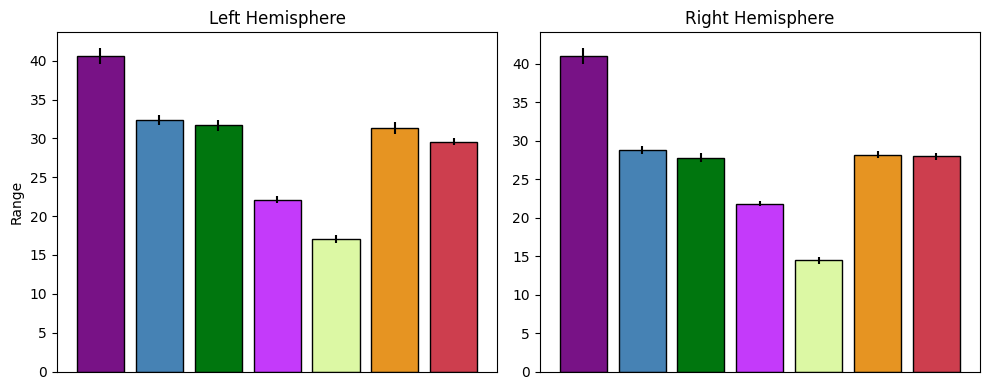

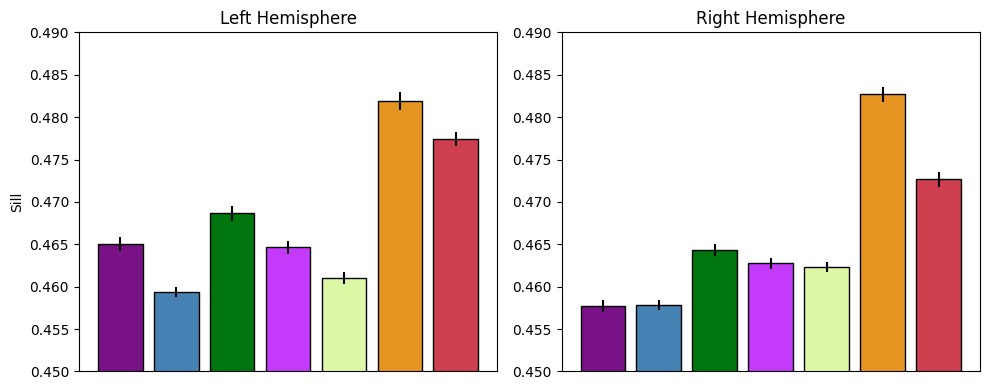

In [156]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# Network labels & colors
# =========================================================
net_names = {
    1: "Visual",
    2: "Somatomotor",
    3: "Dorsal Attention",
    4: "Ventral Attention",
    5: "Limbic",
    6: "Frontoparietal",
    7: "Default Mode"
}

net_colors = {
    1: (120/255, 18/255, 134/255),
    2: (70/255, 130/255, 180/255),
    3: (0/255, 118/255, 14/255),
    4: (196/255, 58/255, 250/255),
    5: (220/255, 248/255, 164/255),
    6: (230/255, 148/255, 34/255),
    7: (205/255, 62/255, 78/255),
}

# =========================================================
# fsLR5k Yeo map
# =========================================================
# shape: (10000,)
# values: 1~7
#
# Example:
# fsLR_5k_yeo = np.load(...)
#
# already assumed loaded
# =========================================================

# ---------------------------------------------------------
# Apply same surface mask
# ---------------------------------------------------------
yeo_l = fsLR_5k_yeo[:4842][mask_5k[:4842] == 1]
yeo_r = fsLR_5k_yeo[4842:][mask_5k[4842:] == 1]

# =========================================================
# RANGE
# =========================================================
fig, axs = plt.subplots(1, 2, figsize=(10,4))

# ---------------------------------------------------------
# LEFT
# ---------------------------------------------------------
ax = axs[0]

for net in range(1, 8):

    mask = (yeo_l == net)

    vals = range_group_l[mask]

    mean_val = np.nanmean(vals)

    # same as reference paper
    sem_val = np.nanstd(vals) / np.sqrt(np.sum(~np.isnan(vals)))

    ax.bar(
        net,
        mean_val,
        yerr=sem_val,
        color=net_colors[net],
        edgecolor='black',
        linewidth=1
    )

ax.set_title("Left Hemisphere")
ax.set_xticks([])
ax.set_ylabel("Range")

# ---------------------------------------------------------
# RIGHT
# ---------------------------------------------------------
ax = axs[1]

for net in range(1, 8):

    mask = (yeo_r == net)

    vals = range_group_r[mask]

    mean_val = np.nanmean(vals)

    sem_val = np.nanstd(vals) / np.sqrt(np.sum(~np.isnan(vals)))

    ax.bar(
        net,
        mean_val,
        yerr=sem_val,
        color=net_colors[net],
        edgecolor='black',
        linewidth=1
    )

ax.set_title("Right Hemisphere")
ax.set_xticks([])

plt.tight_layout()
plt.show()

# =========================================================
# SILL
# =========================================================
fig, axs = plt.subplots(1, 2, figsize=(10,4))

# ---------------------------------------------------------
# LEFT
# ---------------------------------------------------------
ax = axs[0]

for net in range(1, 8):

    mask = (yeo_l == net)

    vals = sill_group_l[mask]

    mean_val = np.nanmean(vals)

    sem_val = np.nanstd(vals) / np.sqrt(np.sum(~np.isnan(vals)))

    ax.bar(
        net,
        mean_val,
        yerr=sem_val,
        color=net_colors[net],
        edgecolor='black',
        linewidth=1
    )

ax.set_title("Left Hemisphere")
ax.set_xticks([])
ax.set_ylabel("Sill")
ax.set_ylim(0.45, 0.49)

# ---------------------------------------------------------
# RIGHT
# ---------------------------------------------------------
ax = axs[1]

for net in range(1, 8):

    mask = (yeo_r == net)

    vals = sill_group_r[mask]

    mean_val = np.nanmean(vals)

    sem_val = np.nanstd(vals) / np.sqrt(np.sum(~np.isnan(vals)))

    ax.bar(
        net,
        mean_val,
        yerr=sem_val,
        color=net_colors[net],
        edgecolor='black',
        linewidth=1
    )

ax.set_title("Right Hemisphere")
ax.set_xticks([])
ax.set_ylim(0.45, 0.49)

plt.tight_layout()
plt.show()